In [1]:
# ============================================================
# UNIFIED 5D QUADRATIC ZERO-SET CLASSIFICATION  (KAGGLE, TRAIN-ONLY)  v2
#
# Ambient dim: 5 | Intrinsic dims: 2,3,4,5 | Degree: 2
# Families: Ellipsoid, Hyperboloid, Paraboloid
# Architectures: PointNet, Vanilla Transformer, CP-GMM
#
# Checkpoints saved per model:
#   best_validation.pt  - epoch with highest validation accuracy
#   best_train.pt       - epoch with highest training accuracy
#   final_epoch.pt      - weights at the moment training stopped
#   last_resume.pt      - rolling resume file (deleted when finished)
#
# Early stopping: train accuracy >= 0.995 on 3 consecutive checks
# (checks happen every 50 epochs). Stops immediately and saves.
#
# NO confusion matrices, NO OOD evaluation, NO ablation.
# Kaggle: Settings -> Accelerator -> GPU. Re-run the cell to resume.
# ============================================================

import os
import json
import time
import random
import math
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    from IPython.display import display, FileLink, HTML
    IN_NOTEBOOK = True
except Exception:
    IN_NOTEBOOK = False


# ============================================================
# 1. CONFIGURATION
# ============================================================

class Config:
    ambient_dim = 5
    intrinsic_dims = [2, 3, 4, 5]
    families = ["Ellipsoid", "Hyperboloid", "Paraboloid"]
    num_classes = len(intrinsic_dims) * len(families)

    num_points = 256

    train_clouds_per_class = 500
    val_clouds_per_class = 100

    batch_size = 256
    epochs = 3000

    learning_rate = 1e-3
    weight_decay = 1e-5

    train_shear_min = 0.5
    train_shear_max = 2.5
    train_noise = 0.05

    # Early stopping on TRAIN accuracy.
    early_stopping = True
    acc_threshold = 0.995      # <-- 99.5%
    check_interval = 50        # check every 50 epochs
    patience = 3               # 3 consecutive qualifying checks

    # Rolling resume checkpoint frequency.
    resume_interval = 50

    seed = 42

    model_names = ["PointNet", "VanillaTransformer", "CPGMM"]


CFG = Config()

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is required. In Kaggle: Settings -> Accelerator -> GPU."
    )

DEVICE = torch.device("cuda")

WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
OUT_DIR = WORK_DIR / "quadratic_5D_experiment"
OUT_DIR.mkdir(parents=True, exist_ok=True)

for _name in CFG.model_names:
    (OUT_DIR / _name / "checkpoints").mkdir(parents=True, exist_ok=True)
    (OUT_DIR / _name / "histories").mkdir(parents=True, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("Output directory:", OUT_DIR.resolve())


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(CFG.seed)


# ============================================================
# 3. CLASS DEFINITIONS
# ============================================================

CLASS_NAMES = []
for d in CFG.intrinsic_dims:
    for family in CFG.families:
        CLASS_NAMES.append(f"{d}D_{family}")


# ============================================================
# 4. QUADRATIC GEOMETRY GENERATOR
# ============================================================

def random_rotation_matrix(dim):
    A = np.random.randn(dim, dim)
    Q, R = np.linalg.qr(A)
    signs = np.sign(np.diag(R))
    signs[signs == 0] = 1
    Q = Q @ np.diag(signs)
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1
    return Q


def sample_intrinsic_geometry(intrinsic_dim, family, n_points):
    """
    Ellipsoid:   sum_i (x_i / a_i)^2 = 1
    Hyperboloid: sum_{i<d} x_i^2 - x_d^2 = 1  (then axis-scaled)
    Paraboloid:  x_d = sum_{i<d} x_i^2        (then axis-scaled)
    """
    d = intrinsic_dim
    scales = np.random.uniform(0.7, 1.5, size=d)

    if family == "Ellipsoid":
        directions = np.random.randn(n_points, d)
        directions /= np.linalg.norm(directions, axis=1, keepdims=True) + 1e-12
        X = directions * scales

    elif family == "Hyperboloid":
        t = np.random.uniform(-1.5, 1.5, size=n_points)
        directions = np.random.randn(n_points, d - 1)
        directions /= np.linalg.norm(directions, axis=1, keepdims=True) + 1e-12
        radius = np.sqrt(1.0 + t ** 2)
        X = np.zeros((n_points, d), dtype=np.float64)
        X[:, :d - 1] = directions * radius[:, None]
        X[:, d - 1] = t
        X *= scales

    elif family == "Paraboloid":
        base = np.random.uniform(-0.8, 0.8, size=(n_points, d - 1))
        X = np.zeros((n_points, d), dtype=np.float64)
        X[:, :d - 1] = base
        X[:, d - 1] = np.sum(base ** 2, axis=1)
        X *= scales

    else:
        raise ValueError(f"Unknown family: {family}")

    return X


def embed_in_5d(X, intrinsic_dim):
    embedded = np.zeros((X.shape[0], CFG.ambient_dim), dtype=np.float64)
    embedded[:, :intrinsic_dim] = X
    return embedded


# ============================================================
# 5. ROTATION, SHEAR AND NOISE
# ============================================================

def apply_random_shear(X, shear_magnitude):
    D = X.shape[1]
    S = np.eye(D)
    for i in range(D):
        for j in range(i + 1, D):
            S[i, j] = np.random.uniform(-1.0, 1.0) * shear_magnitude
    return X @ S.T


def transform_cloud(X, shear_magnitude, noise_level):
    Q = random_rotation_matrix(CFG.ambient_dim)
    X = X @ Q.T
    X = apply_random_shear(X, shear_magnitude)
    X = X - X.mean(axis=0, keepdims=True)
    X += np.random.normal(0.0, noise_level, size=X.shape)
    rms = np.sqrt(np.mean(np.sum(X ** 2, axis=1))) + 1e-8
    X = X / rms
    return X.astype(np.float32)


# ============================================================
# 6. DATASET GENERATION (TRAIN + VALIDATION ONLY)
# ============================================================

def generate_dataset(clouds_per_class):
    all_clouds, all_labels = [], []

    for dim_idx, intrinsic_dim in enumerate(CFG.intrinsic_dims):
        for family_idx, family in enumerate(CFG.families):
            class_id = dim_idx * len(CFG.families) + family_idx

            for _ in range(clouds_per_class):
                X_int = sample_intrinsic_geometry(
                    intrinsic_dim, family, CFG.num_points
                )
                X_5d = embed_in_5d(X_int, intrinsic_dim)

                shear = np.random.uniform(
                    CFG.train_shear_min, CFG.train_shear_max
                )
                X_final = transform_cloud(X_5d, shear, CFG.train_noise)

                all_clouds.append(X_final)
                all_labels.append(class_id)

    X = np.asarray(all_clouds, dtype=np.float32)
    y = np.asarray(all_labels, dtype=np.int64)

    idx = np.random.permutation(len(y))
    return X[idx], y[idx]


print("\nGenerating training dataset...")
X_train_np, y_train_np = generate_dataset(CFG.train_clouds_per_class)
print("Generating validation dataset...")
X_val_np, y_val_np = generate_dataset(CFG.val_clouds_per_class)

# Datasets are tiny: keep them resident on the GPU.
X_TRAIN = torch.from_numpy(X_train_np).to(DEVICE)
Y_TRAIN = torch.from_numpy(y_train_np).to(DEVICE)
X_VAL = torch.from_numpy(X_val_np).to(DEVICE)
Y_VAL = torch.from_numpy(y_val_np).to(DEVICE)

print(f"Train: {tuple(X_TRAIN.shape)} | Val: {tuple(X_VAL.shape)}")


def iterate_batches(X, y, batch_size, shuffle, generator=None):
    n = X.shape[0]
    if shuffle:
        order = torch.randperm(n, generator=generator).to(X.device)
    else:
        order = torch.arange(n, device=X.device)
    for start in range(0, n, batch_size):
        idx = order[start:start + batch_size]
        yield X[idx], y[idx]


# ============================================================
# 7. MODEL 1: POINTNET
# ============================================================

class PointNetClassifier(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.point_mlp = nn.Sequential(
            nn.Conv1d(5, 64, 1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, 1), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Conv1d(128, 256, 1), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Conv1d(256, 512, 1), nn.BatchNorm1d(512), nn.ReLU(),
        )

        self.classifier = nn.Sequential(
            nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, num_classes),
        )

    def forward(self, X):
        X = X.transpose(1, 2)
        features = self.point_mlp(X)
        pooled = torch.max(features, dim=2)[0]
        return self.classifier(pooled)


# ============================================================
# 8. MODEL 2: VANILLA TRANSFORMER
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(self, dim=128, heads=8):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attention = nn.MultiheadAttention(
            embed_dim=dim, num_heads=heads, batch_first=True
        )
        self.norm2 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4), nn.GELU(), nn.Linear(dim * 4, dim)
        )

    def forward(self, X):
        Z = self.norm1(X)
        attended, _ = self.attention(Z, Z, Z, need_weights=False)
        X = X + attended
        X = X + self.ffn(self.norm2(X))
        return X


class VanillaTransformer(nn.Module):

    def __init__(self, num_classes):
        super().__init__()
        self.embedding = nn.Linear(5, 128)
        self.blocks = nn.Sequential(
            TransformerBlock(128, 8),
            TransformerBlock(128, 8),
            TransformerBlock(128, 8),
        )
        self.norm = nn.LayerNorm(128)
        self.classifier = nn.Sequential(
            nn.Linear(128, 256), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, X):
        X = self.embedding(X)
        X = self.blocks(X)
        X = self.norm(X)
        X = X.mean(dim=1)
        return self.classifier(X)


# ============================================================
# 9. QUADRATIC VERONESE LIFT
# ============================================================

def quadratic_veronese(X):
    """x_i*x_j (i<=j), x_i, 1  ->  21 terms in 5D."""
    B, N, D = X.shape
    terms = []
    for i in range(D):
        for j in range(i, D):
            terms.append(X[:, :, i] * X[:, :, j])
    for i in range(D):
        terms.append(X[:, :, i])
    terms.append(torch.ones_like(X[:, :, 0]))
    return torch.stack(terms, dim=-1)


def coefficient_matrix_from_vector(c):
    """Symmetric 5x5 quadratic matrix from the first 15 Veronese coefficients."""
    B = c.shape[0]
    A = torch.zeros(B, 5, 5, device=c.device, dtype=c.dtype)
    index = 0
    for i in range(5):
        for j in range(i, 5):
            value = c[:, index]
            if i == j:
                A[:, i, j] = value
            else:
                A[:, i, j] = value / 2.0
                A[:, j, i] = value / 2.0
            index += 1
    return A


# ============================================================
# 10. MODEL 3: CP-GMM
# ============================================================

class CPAttentionBlock(nn.Module):

    def __init__(self, dim=128, heads=8):
        super().__init__()
        self.dim = dim
        self.heads = heads
        self.head_dim = dim // heads

        self.norm1 = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, dim * 3)
        self.projection = nn.Linear(dim, dim)
        self.norm2 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4), nn.GELU(), nn.Linear(dim * 4, dim)
        )

    def forward(self, X, geometric_bias, alpha):
        B, N, D = X.shape
        Z = self.norm1(X)

        qkv = self.qkv(Z).reshape(B, N, 3, self.heads, self.head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4)

        attention = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        attention = attention + alpha * geometric_bias[:, None, :, :]
        attention = torch.softmax(attention, dim=-1)

        output = (attention @ v).transpose(1, 2).reshape(B, N, D)

        X = X + self.projection(output)
        X = X + self.ffn(self.norm2(X))
        return X


class CPGMMNetwork(nn.Module):
    """
    Template-routing architecture:
      1. Quadratic Veronese lift.
      2. Algebraic coefficient estimation (smallest right-singular vector).
      3. Learned template routing.
      4. Coefficient-conditioned geometric attention bias.
    """

    def __init__(self, num_classes):
        super().__init__()
        self.num_classes = num_classes

        self.embedding = nn.Linear(5 + 21, 128)

        self.router = nn.Sequential(
            nn.Linear(42, 128), nn.LayerNorm(128), nn.GELU(),
            nn.Linear(128, 64), nn.GELU(),
        )

        self.templates = nn.Parameter(torch.randn(num_classes, 64) * 0.02)
        self.router_temperature = 1.0
        self.template_projection = nn.Linear(64, 128)

        self.blocks = nn.ModuleList([
            CPAttentionBlock(128, 8),
            CPAttentionBlock(128, 8),
            CPAttentionBlock(128, 8),
        ])

        self.alpha = nn.Parameter(torch.tensor(1e-3))
        self.norm = nn.LayerNorm(128)

        self.classifier = nn.Sequential(
            nn.Linear(128, 256), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def algebraic_features(self, X):
        with torch.no_grad():
            lifted = quadratic_veronese(X)                  # [B, N, 21]

            # Right-singular vectors / singular values of `lifted` via the
            # 21x21 Gram matrix in float64 (equivalent to batched SVD, faster).
            L64 = lifted.double()
            gram = L64.transpose(1, 2) @ L64                # [B, 21, 21]
            eigvals, eigvecs = torch.linalg.eigh(gram)      # ascending

            coefficients = eigvecs[:, :, 0]                 # smallest direction
            singular_values = torch.sqrt(
                torch.clamp(eigvals.flip(dims=[1]), min=0.0)  # descending
            )

            coefficients = coefficients.float()
            singular_values = singular_values.float()

            sign = torch.where(
                coefficients[:, 0:1] < 0,
                -torch.ones_like(coefficients[:, 0:1]),
                torch.ones_like(coefficients[:, 0:1]),
            )
            coefficients = coefficients * sign

            singular_values = singular_values / (
                singular_values.norm(dim=1, keepdim=True) + 1e-8
            )

            algebraic_input = torch.cat([coefficients, singular_values], dim=1)

        return lifted, coefficients, algebraic_input

    def forward(self, X):
        lifted, coefficients, algebraic_input = self.algebraic_features(X)

        router_features = self.router(algebraic_input)
        normalized_router = F.normalize(router_features, dim=1)
        normalized_templates = F.normalize(self.templates, dim=1)

        routing_logits = (
            normalized_router @ normalized_templates.T
        ) / self.router_temperature
        routing_weights = torch.softmax(routing_logits, dim=-1)

        routed_template = routing_weights @ self.templates
        routed_embedding = self.template_projection(routed_template)

        A = coefficient_matrix_from_vector(coefficients)
        geometric_bias = (X @ A @ X.transpose(1, 2)) / math.sqrt(21)

        tokens = torch.cat([X, lifted], dim=-1)
        tokens = self.embedding(tokens)
        tokens = tokens + routed_embedding[:, None, :]

        for block in self.blocks:
            tokens = block(tokens, geometric_bias, self.alpha)

        pooled = self.norm(tokens.mean(dim=1))
        logits = self.classifier(pooled)

        return logits, routing_weights


# ============================================================
# 11. MODEL FACTORY / HELPERS
# ============================================================

def build_model(name):
    if name == "PointNet":
        return PointNetClassifier(CFG.num_classes)
    if name == "VanillaTransformer":
        return VanillaTransformer(CFG.num_classes)
    if name == "CPGMM":
        return CPGMMNetwork(CFG.num_classes)
    raise ValueError(name)


def get_logits(output):
    return output[0] if isinstance(output, tuple) else output


@torch.no_grad()
def evaluate_model(model, X, y):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss, total_correct, total = 0.0, 0, 0

    for xb, yb in iterate_batches(X, y, CFG.batch_size, shuffle=False):
        logits = get_logits(model(xb))
        loss = criterion(logits, yb)
        total_loss += loss.item() * yb.size(0)
        total_correct += (logits.argmax(dim=1) == yb).sum().item()
        total += yb.size(0)

    return {"loss": total_loss / total, "accuracy": total_correct / total}


# ============================================================
# 12. CHECKPOINTS AND DOWNLOAD
# ============================================================

def atomic_torch_save(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def save_checkpoint(path, model, optimizer, scheduler, epoch, state,
                    model_name, history, full=True):
    """
    state: dict with best_val_accuracy, best_val_epoch,
           best_train_accuracy, best_train_epoch, streak.
    """
    ckpt = {
        "model_name": model_name,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "best_val_accuracy": state["best_val_accuracy"],
        "best_val_epoch": state["best_val_epoch"],
        "best_train_accuracy": state["best_train_accuracy"],
        "best_train_epoch": state["best_train_epoch"],
        "streak": state["streak"],
        "history": history,
        "config": {
            "ambient_dim": CFG.ambient_dim,
            "intrinsic_dims": CFG.intrinsic_dims,
            "families": CFG.families,
            "num_classes": CFG.num_classes,
            "num_points": CFG.num_points,
            "epochs": CFG.epochs,
            "seed": CFG.seed,
            "acc_threshold": CFG.acc_threshold,
        },
        "class_names": CLASS_NAMES,
    }
    if full:
        ckpt["optimizer_state_dict"] = optimizer.state_dict()
        ckpt["scheduler_state_dict"] = scheduler.state_dict()
    atomic_torch_save(ckpt, path)


def offer_download(model_name):
    """
    Zips best-val + best-train + final checkpoints (+ history/summary) and
    shows a link. Safari will not let a notebook auto-start a download, so
    one click on the link is needed. The zip also appears in the Output panel
    (right sidebar) under /kaggle/working.
    """
    model_dir = OUT_DIR / model_name
    zip_path = WORK_DIR / f"{model_name}_checkpoints.zip"

    files = [
        model_dir / "checkpoints" / "best_validation.pt",
        model_dir / "checkpoints" / "best_train.pt",
        model_dir / "checkpoints" / "final_epoch.pt",
        model_dir / "histories" / "training_history.csv",
        model_dir / "training_summary.json",
    ]

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for f in files:
            if f.exists():
                z.write(f, arcname=f"{model_name}/{f.relative_to(model_dir)}")

    size_mb = zip_path.stat().st_size / (1024 ** 2)
    print(f"[{model_name}] Download bundle ready: {zip_path} ({size_mb:.1f} MB)")

    if IN_NOTEBOOK:
        try:
            display(FileLink(os.path.relpath(zip_path, Path.cwd())))
        except Exception as e:
            print("Could not render link:", e)
        display(HTML(
            "<b>Click the link above to download.</b> If it does not work, open the "
            "<i>Output</i> panel (right sidebar) &rarr; /kaggle/working and download "
            f"<code>{zip_path.name}</code>."
        ))


# ============================================================
# 13. TRAINING LOOP (WITH RESUME)
# ============================================================

def train_model(model_name):

    print("\n" + "=" * 75)
    print(f"TRAINING: {model_name}")
    print("=" * 75)

    model_dir = OUT_DIR / model_name
    checkpoint_dir = model_dir / "checkpoints"
    history_dir = model_dir / "histories"

    best_val_path = checkpoint_dir / "best_validation.pt"
    best_train_path = checkpoint_dir / "best_train.pt"
    final_path = checkpoint_dir / "final_epoch.pt"
    last_path = checkpoint_dir / "last_resume.pt"
    done_flag = model_dir / "DONE.flag"
    summary_path = model_dir / "training_summary.json"

    # Finished in a previous run -> skip.
    if done_flag.exists():
        print(f"[{model_name}] Already completed. Skipping training.")
        offer_download(model_name)
        with open(summary_path) as f:
            return json.load(f)

    seed_everything(CFG.seed)

    model = build_model(model_name).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CFG.learning_rate,
        weight_decay=CFG.weight_decay,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=CFG.epochs
    )
    criterion = nn.CrossEntropyLoss()

    shuffle_gen = torch.Generator()
    shuffle_gen.manual_seed(CFG.seed + 100)

    history = []
    state = {
        "best_val_accuracy": -1.0,
        "best_val_epoch": -1,
        "best_train_accuracy": -1.0,
        "best_train_epoch": -1,
        "streak": 0,
    }
    start_epoch = 1
    elapsed_before = 0.0

    # ---------------- resume ----------------
    if last_path.exists():
        ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model_state_dict"])
        optimizer.load_state_dict(ck["optimizer_state_dict"])
        scheduler.load_state_dict(ck["scheduler_state_dict"])
        history = ck["history"]
        state = ck["state"]
        start_epoch = ck["epoch"] + 1
        shuffle_gen.manual_seed(CFG.seed + 100 + start_epoch)
        elapsed_before = ck.get("elapsed", 0.0)
        print(f"[{model_name}] RESUMING from epoch {ck['epoch']} "
              f"(best val {state['best_val_accuracy']:.4f}, "
              f"best train {state['best_train_accuracy']:.6f})")

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    start_time = time.perf_counter()

    early_stopped = False
    actual_epochs = start_epoch - 1

    for epoch in range(start_epoch, CFG.epochs + 1):

        actual_epochs = epoch
        model.train()

        epoch_loss, epoch_correct, epoch_samples = 0.0, 0, 0

        for xb, yb in iterate_batches(
            X_TRAIN, Y_TRAIN, CFG.batch_size, shuffle=True, generator=shuffle_gen
        ):
            optimizer.zero_grad(set_to_none=True)

            logits = get_logits(model(xb))
            loss = criterion(logits, yb)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            epoch_loss += loss.item() * yb.size(0)
            epoch_correct += (logits.argmax(dim=1) == yb).sum().item()
            epoch_samples += yb.size(0)

        scheduler.step()

        train_loss = epoch_loss / epoch_samples
        train_accuracy = epoch_correct / epoch_samples

        val = evaluate_model(model, X_VAL, Y_VAL)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val["loss"],
            "val_accuracy": val["accuracy"],
            "learning_rate": optimizer.param_groups[0]["lr"],
        })

        # ---- best-validation checkpoint ----
        if val["accuracy"] > state["best_val_accuracy"]:
            state["best_val_accuracy"] = val["accuracy"]
            state["best_val_epoch"] = epoch
            save_checkpoint(
                best_val_path, model, optimizer, scheduler, epoch, state,
                model_name, history, full=False,
            )

        # ---- best-TRAIN-accuracy checkpoint ----
        if train_accuracy > state["best_train_accuracy"]:
            state["best_train_accuracy"] = train_accuracy
            state["best_train_epoch"] = epoch
            save_checkpoint(
                best_train_path, model, optimizer, scheduler, epoch, state,
                model_name, history, full=False,
            )

        # ---- logging ----
        if epoch == 1 or epoch % CFG.check_interval == 0 or epoch == CFG.epochs:
            print(
                f"[{model_name}] Epoch {epoch:04d}/{CFG.epochs} | "
                f"Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.6f} | "
                f"Val Loss: {val['loss']:.4f} | Val Acc: {val['accuracy']:.4f} | "
                f"Best Val: {state['best_val_accuracy']:.4f} | "
                f"Best Train: {state['best_train_accuracy']:.6f}",
                flush=True,
            )

        # ---- early stopping on train accuracy (every check_interval) ----
        if epoch % CFG.check_interval == 0:
            if train_accuracy >= CFG.acc_threshold:
                state["streak"] += 1
            else:
                state["streak"] = 0

            print(f"[{model_name}] Train-acc check: {train_accuracy:.6f} "
                  f"(threshold {CFG.acc_threshold}) | "
                  f"Streak: {state['streak']}/{CFG.patience}")

            if CFG.early_stopping and state["streak"] >= CFG.patience:
                early_stopped = True
                print(f"[{model_name}] EARLY STOPPING at epoch {epoch}. "
                      f"Saving model and exiting training.")

        # ---- rolling resume checkpoint ----
        if epoch % CFG.resume_interval == 0 and not early_stopped:
            atomic_torch_save({
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "epoch": epoch,
                "history": history,
                "state": state,
                "elapsed": elapsed_before + (time.perf_counter() - start_time),
            }, last_path)
            pd.DataFrame(history).to_csv(
                history_dir / "training_history.csv", index=False
            )

        if early_stopped:
            break

    # ---------------- finish ----------------
    torch.cuda.synchronize()
    training_time = elapsed_before + (time.perf_counter() - start_time)
    peak_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)

    save_checkpoint(
        final_path, model, optimizer, scheduler, actual_epochs, state,
        model_name, history, full=True,
    )

    pd.DataFrame(history).to_csv(
        history_dir / "training_history.csv", index=False
    )

    summary = {
        "model": model_name,
        "actual_epochs": actual_epochs,
        "maximum_epochs": CFG.epochs,
        "early_stopping_triggered": early_stopped,
        "early_stopping_metric": "train_accuracy",
        "early_stopping_threshold": CFG.acc_threshold,
        "checkpoint_interval": CFG.check_interval,
        "early_stopping_patience": CFG.patience,
        "best_validation_accuracy": state["best_val_accuracy"],
        "best_validation_epoch": state["best_val_epoch"],
        "best_train_accuracy": state["best_train_accuracy"],
        "best_train_epoch": state["best_train_epoch"],
        "final_train_accuracy": history[-1]["train_accuracy"] if history else 0.0,
        "final_validation_accuracy": history[-1]["val_accuracy"] if history else 0.0,
        "training_time_seconds": training_time,
        "seconds_per_epoch": training_time / max(actual_epochs, 1),
        "peak_gpu_memory_mb": peak_memory_mb,
        "parameter_count": sum(p.numel() for p in model.parameters()),
    }

    with open(summary_path, "w") as f:
        json.dump(summary, f, indent=4)

    done_flag.write_text("done")
    if last_path.exists():
        last_path.unlink()

    print("\n" + "=" * 75)
    print(f"{model_name} TRAINING COMPLETED")
    print("=" * 75)
    print(f"Actual epochs:             {actual_epochs}")
    print(f"Early stopping triggered:  {early_stopped}")
    print(f"Best val acc:              {state['best_val_accuracy']:.4f} "
          f"(epoch {state['best_val_epoch']})")
    print(f"Best train acc:            {state['best_train_accuracy']:.6f} "
          f"(epoch {state['best_train_epoch']})")
    print(f"Training time:             {training_time / 60:.2f} min")
    print(f"Peak GPU memory:           {peak_memory_mb:.1f} MB")
    print(f"best_validation.pt:        {best_val_path}")
    print(f"best_train.pt:             {best_train_path}")
    print(f"final_epoch.pt:            {final_path}")

    offer_download(model_name)

    return summary


# ============================================================
# 14. RUN
# ============================================================

training_summaries = []

for model_name in CFG.model_names:
    training_summaries.append(train_model(model_name))

summary_df = pd.DataFrame(training_summaries)
summary_df.to_csv(OUT_DIR / "training_comparison.csv", index=False)

with open(OUT_DIR / "experiment_config.json", "w") as f:
    json.dump({
        "ambient_dimension": CFG.ambient_dim,
        "intrinsic_dimensions": CFG.intrinsic_dims,
        "polynomial_degree": 2,
        "geometric_families": CFG.families,
        "class_names": CLASS_NAMES,
        "architectures": CFG.model_names,
        "max_epochs": CFG.epochs,
        "early_stopping_threshold": CFG.acc_threshold,
        "training_noise": CFG.train_noise,
        "points_per_cloud": CFG.num_points,
        "batch_size": CFG.batch_size,
        "seed": CFG.seed,
        "device": torch.cuda.get_device_name(0),
    }, f, indent=4)

# One bundle with everything.
all_zip = WORK_DIR / "ALL_checkpoints.zip"
with zipfile.ZipFile(all_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT_DIR.rglob("*"):
        if p.is_file() and p.suffix != ".tmp":
            z.write(p, arcname=str(p.relative_to(OUT_DIR)))

print("\n" + "=" * 75)
print("ALL TRAINING COMPLETE")
print("=" * 75)
print(summary_df)
print("\nAll checkpoints bundled in:", all_zip)

if IN_NOTEBOOK:
    display(FileLink(os.path.relpath(all_zip, Path.cwd())))

GPU: Tesla T4
Output directory: /kaggle/working/quadratic_5D_experiment

Generating training dataset...
Generating validation dataset...
Train: (6000, 256, 5) | Val: (1200, 256, 5)

TRAINING: PointNet
[PointNet] Epoch 0001/3000 | Train Loss: 2.3653 | Train Acc: 0.130000 | Val Loss: 2.5259 | Val Acc: 0.0942 | Best Val: 0.0942 | Best Train: 0.130000
[PointNet] Epoch 0050/3000 | Train Loss: 0.1114 | Train Acc: 0.959667 | Val Loss: 0.4841 | Val Acc: 0.8542 | Best Val: 0.9267 | Best Train: 0.968000
[PointNet] Train-acc check: 0.959667 (threshold 0.995) | Streak: 0/3
[PointNet] Epoch 0100/3000 | Train Loss: 0.0664 | Train Acc: 0.977500 | Val Loss: 0.3504 | Val Acc: 0.9017 | Best Val: 0.9375 | Best Train: 0.982667
[PointNet] Train-acc check: 0.977500 (threshold 0.995) | Streak: 0/3
[PointNet] Epoch 0150/3000 | Train Loss: 0.0395 | Train Acc: 0.987333 | Val Loss: 0.2776 | Val Acc: 0.9325 | Best Val: 0.9375 | Best Train: 0.988667
[PointNet] Train-acc check: 0.987333 (threshold 0.995) | Streak: 

/kaggle/working/PointNet_checkpoints.zip


TRAINING: VanillaTransformer
[VanillaTransformer] Epoch 0001/3000 | Train Loss: 2.5055 | Train Acc: 0.073667 | Val Loss: 2.4873 | Val Acc: 0.0850 | Best Val: 0.0850 | Best Train: 0.073667
[VanillaTransformer] Epoch 0050/3000 | Train Loss: 0.1492 | Train Acc: 0.942333 | Val Loss: 0.6753 | Val Acc: 0.8067 | Best Val: 0.8192 | Best Train: 0.953000
[VanillaTransformer] Train-acc check: 0.942333 (threshold 0.995) | Streak: 0/3
[VanillaTransformer] Epoch 0100/3000 | Train Loss: 0.0461 | Train Acc: 0.984333 | Val Loss: 0.8231 | Val Acc: 0.8267 | Best Val: 0.8325 | Best Train: 0.987000
[VanillaTransformer] Train-acc check: 0.984333 (threshold 0.995) | Streak: 0/3
[VanillaTransformer] Epoch 0150/3000 | Train Loss: 0.0381 | Train Acc: 0.987000 | Val Loss: 0.9815 | Val Acc: 0.8233 | Best Val: 0.8417 | Best Train: 0.992500
[VanillaTransformer] Train-acc check: 0.987000 (threshold 0.995) | Streak: 0/3
[VanillaTransformer] Epoch 0200/3000 | Train Loss: 0.0367 | Train Acc: 0.987000 | Val Loss: 0.965

/kaggle/working/VanillaTransformer_checkpoints.zip


TRAINING: CPGMM
[CPGMM] Epoch 0001/3000 | Train Loss: 2.5060 | Train Acc: 0.078500 | Val Loss: 2.4862 | Val Acc: 0.1208 | Best Val: 0.1208 | Best Train: 0.078500
[CPGMM] Epoch 0050/3000 | Train Loss: 0.1077 | Train Acc: 0.963000 | Val Loss: 0.1680 | Val Acc: 0.9408 | Best Val: 0.9500 | Best Train: 0.965333
[CPGMM] Train-acc check: 0.963000 (threshold 0.995) | Streak: 0/3
[CPGMM] Epoch 0100/3000 | Train Loss: 0.0972 | Train Acc: 0.967000 | Val Loss: 0.2478 | Val Acc: 0.9350 | Best Val: 0.9617 | Best Train: 0.988333
[CPGMM] Train-acc check: 0.967000 (threshold 0.995) | Streak: 0/3
[CPGMM] Epoch 0150/3000 | Train Loss: 0.0273 | Train Acc: 0.990500 | Val Loss: 0.1490 | Val Acc: 0.9608 | Best Val: 0.9683 | Best Train: 0.995500
[CPGMM] Train-acc check: 0.990500 (threshold 0.995) | Streak: 0/3
[CPGMM] Epoch 0200/3000 | Train Loss: 0.0208 | Train Acc: 0.992833 | Val Loss: 0.1444 | Val Acc: 0.9625 | Best Val: 0.9733 | Best Train: 0.998833
[CPGMM] Train-acc check: 0.992833 (threshold 0.995) | S

/kaggle/working/CPGMM_checkpoints.zip


ALL TRAINING COMPLETE
                model  actual_epochs  maximum_epochs  \
0            PointNet            700            3000   
1  VanillaTransformer            600            3000   
2               CPGMM            350            3000   

   early_stopping_triggered early_stopping_metric  early_stopping_threshold  \
0                      True        train_accuracy                     0.995   
1                      True        train_accuracy                     0.995   
2                      True        train_accuracy                     0.995   

   checkpoint_interval  early_stopping_patience  best_validation_accuracy  \
0                   50                        3                    0.9450   
1                   50                        3                    0.8500   
2                   50                        3                    0.9775   

   best_validation_epoch  best_train_accuracy  best_train_epoch  \
0                    171             0.998833              

/kaggle/working/ALL_checkpoints.zip

In [3]:

loaded_models = {}
checkpoint_metadata = {}

for name in MODEL_NAMES:

    checkpoint_path = (
        EXTRACT_DIR
        / name
        / "checkpoints"
        / "best_validation.pt"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model = build_model(name).to(DEVICE)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    loaded_models[name] = model

    checkpoint_metadata[name] = {
        "checkpoint_epoch": checkpoint["epoch"],
        "best_validation_accuracy": checkpoint["best_val_accuracy"]
    }

    print(
        f"{name}: loaded successfully | "
        f"Epoch: {checkpoint['epoch']} | "
        f"Recorded validation accuracy: "
        f"{checkpoint['best_val_accuracy']:.4f}"
    )

print("\nAll three architectures loaded successfully.")


PointNet: loaded successfully | Epoch: 171 | Recorded validation accuracy: 0.9450
VanillaTransformer: loaded successfully | Epoch: 437 | Recorded validation accuracy: 0.8500
CPGMM: loaded successfully | Epoch: 308 | Recorded validation accuracy: 0.9775

All three architectures loaded successfully.


All three best-validation checkpoints verified.
Shear 1: X=(1200, 256, 5), y=(1200,)
Shear 5: X=(1200, 256, 5), y=(1200,)
Shear 12: X=(1200, 256, 5), y=(1200,)
Shear 20: X=(1200, 256, 5), y=(1200,)
Shear 30: X=(1200, 256, 5), y=(1200,)

EVALUATING: PointNet


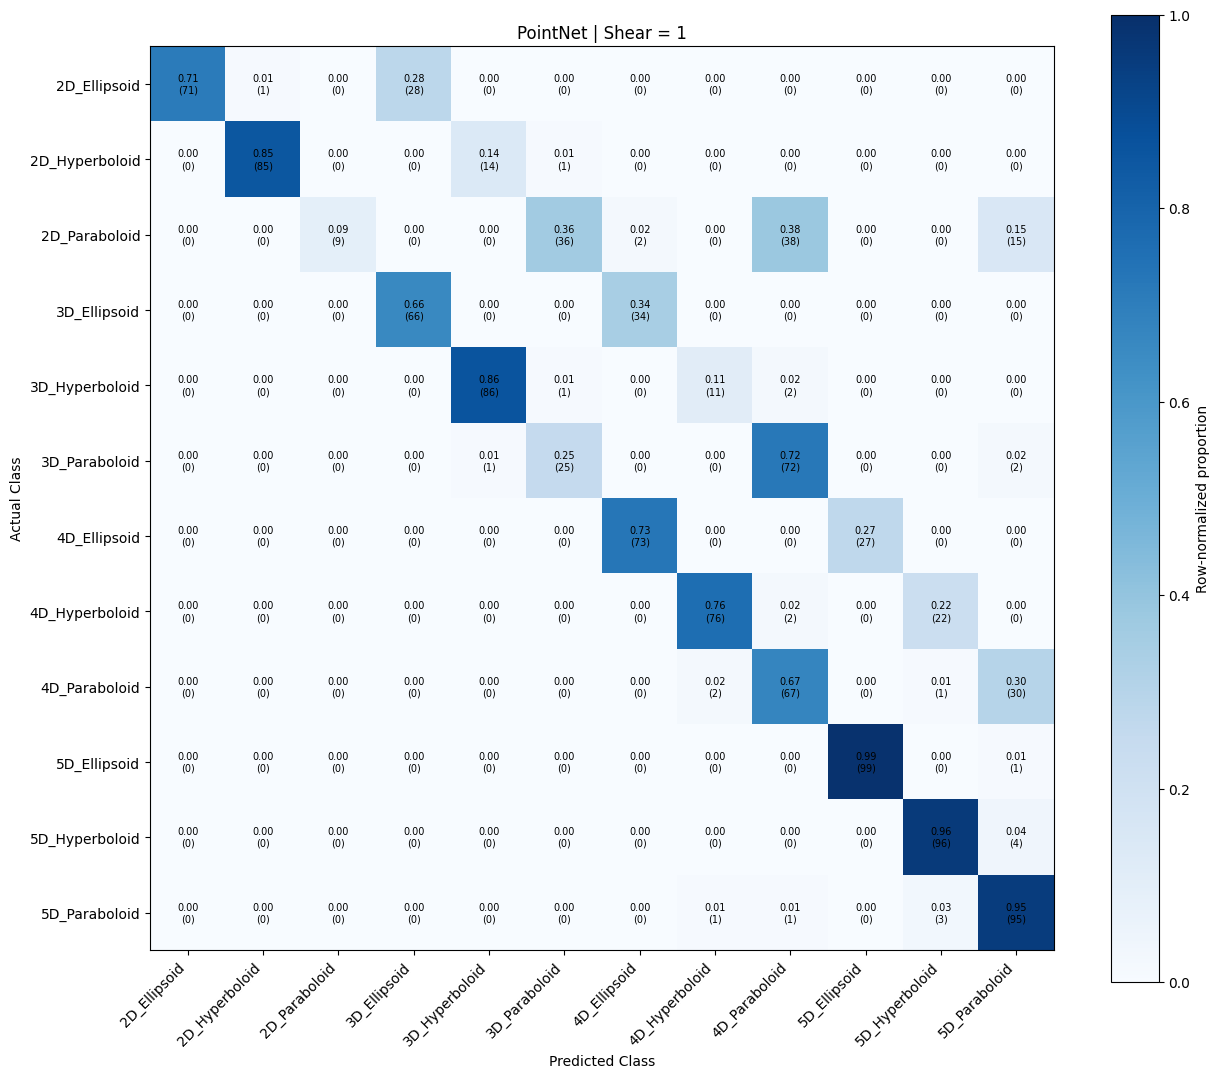

PointNet | Shear  1 | Accuracy: 0.7067


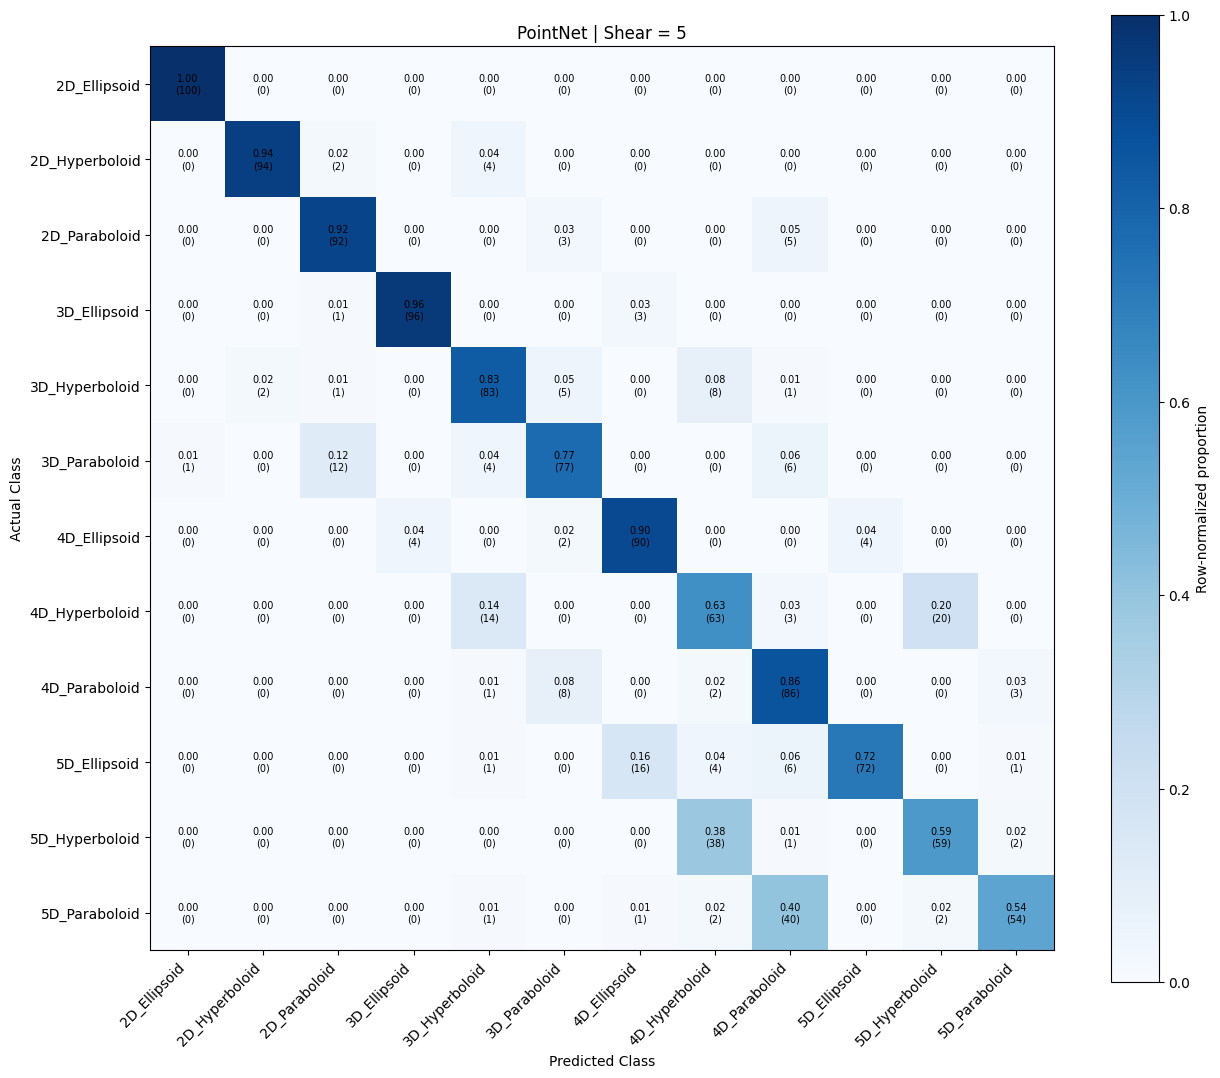

PointNet | Shear  5 | Accuracy: 0.8050


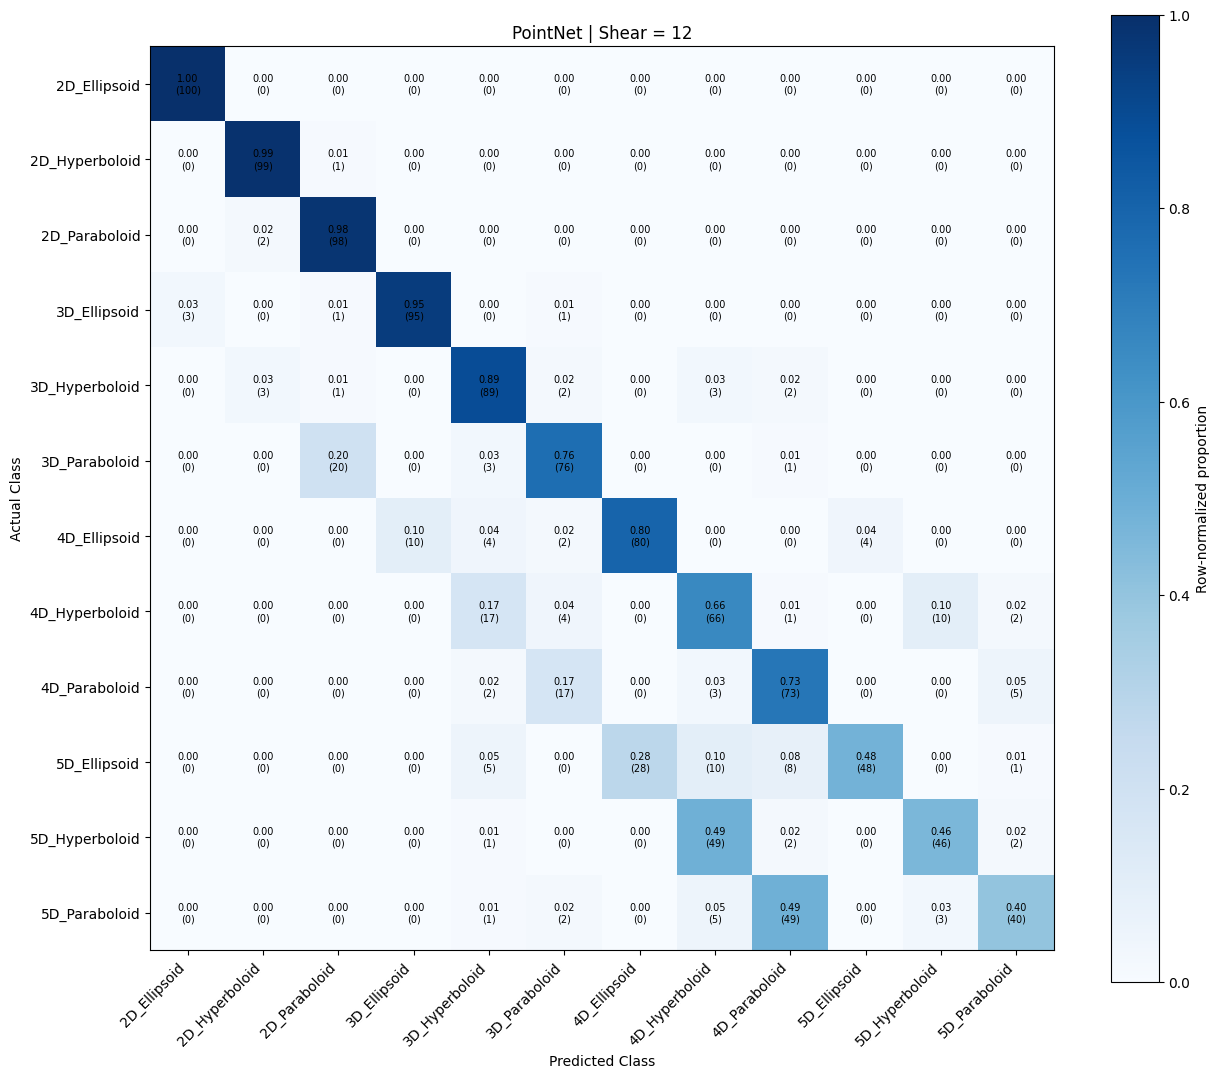

PointNet | Shear 12 | Accuracy: 0.7583


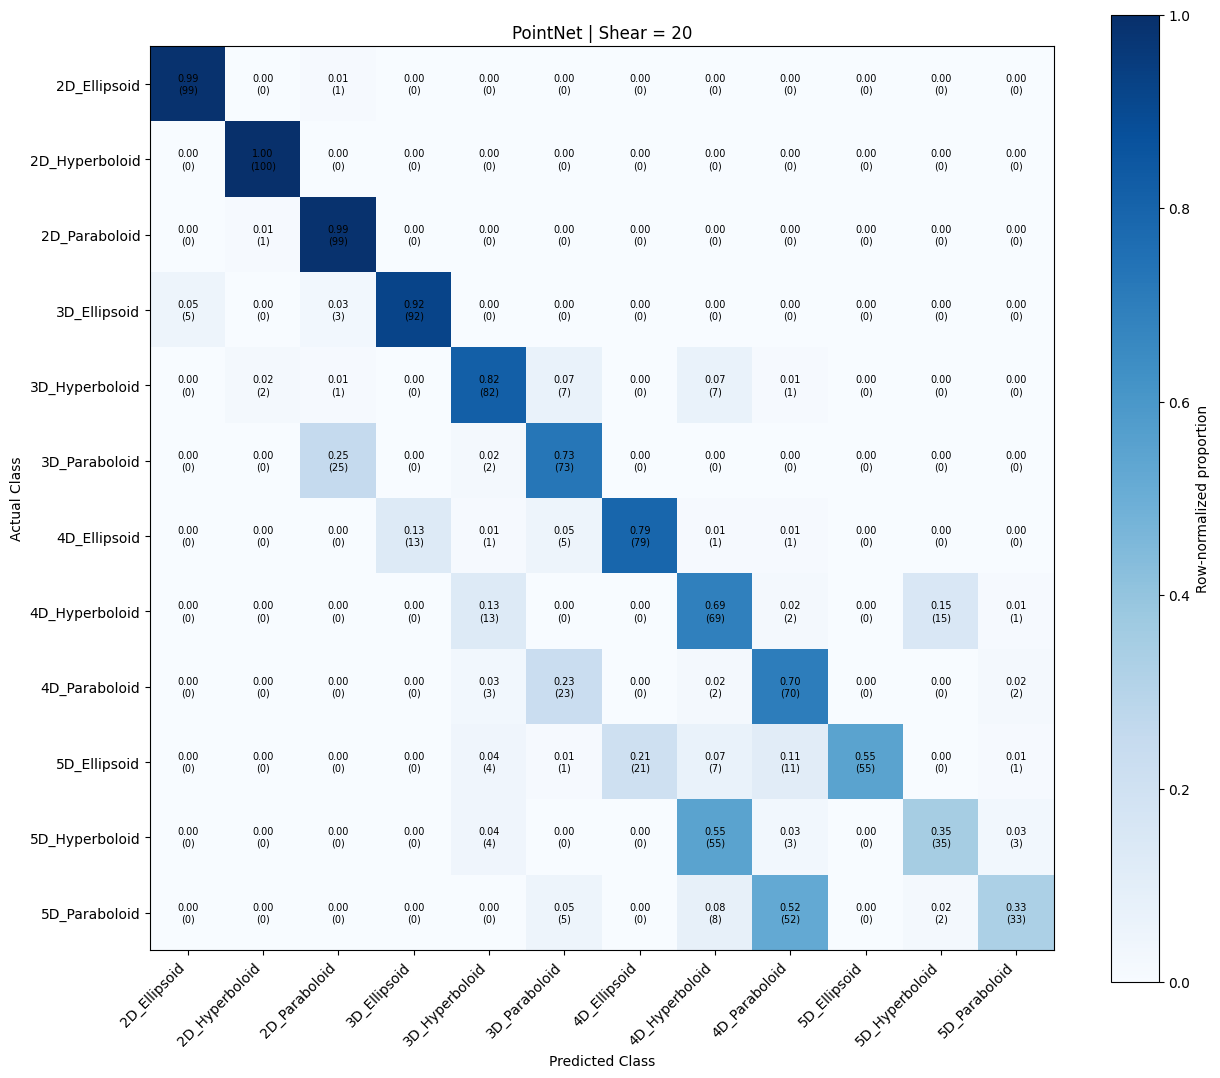

PointNet | Shear 20 | Accuracy: 0.7383


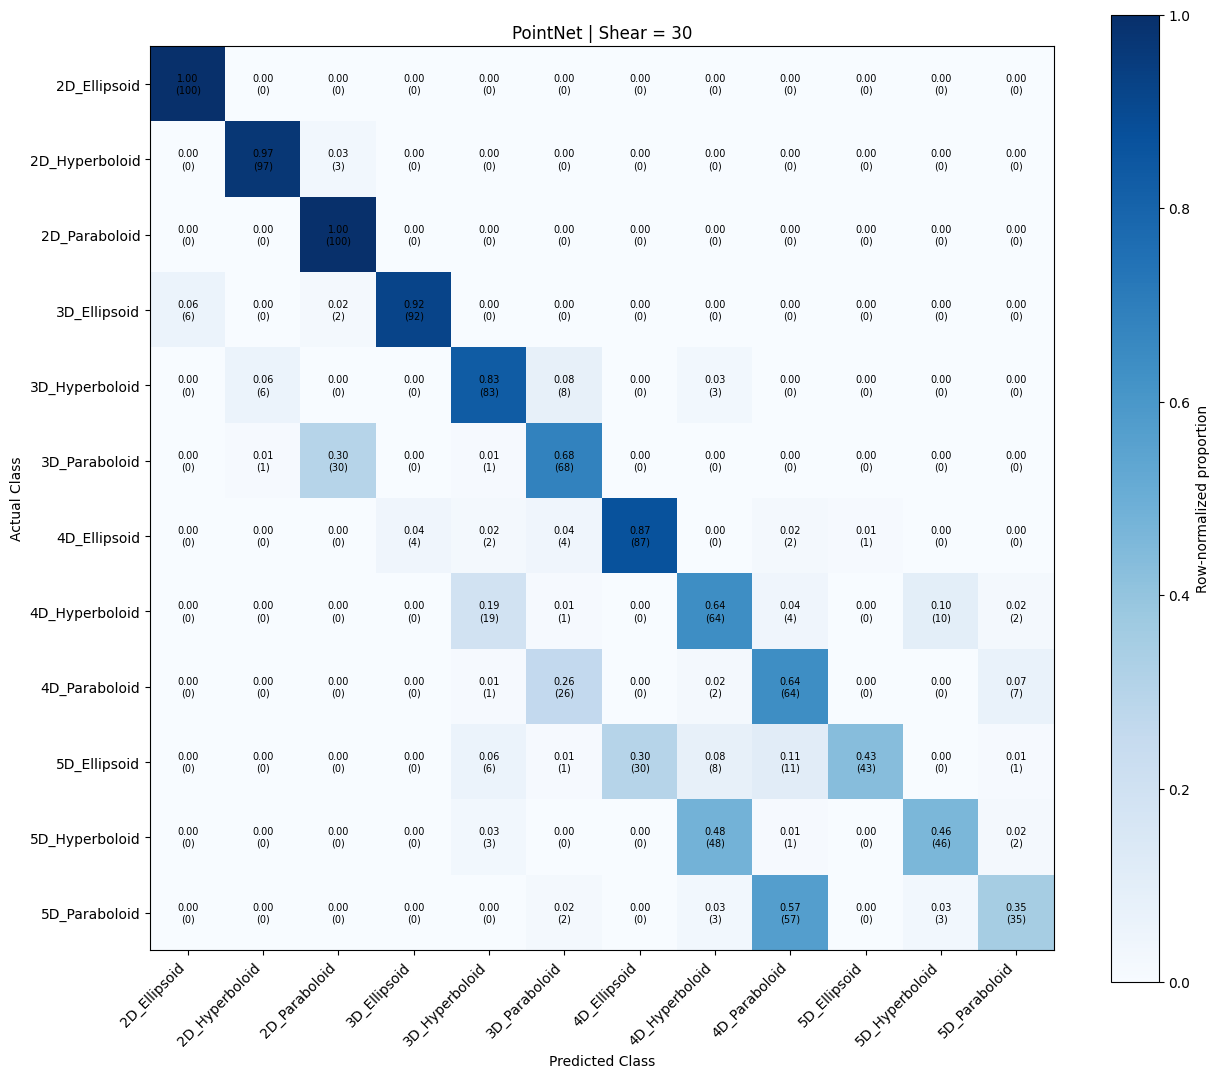

PointNet | Shear 30 | Accuracy: 0.7325

EVALUATING: VanillaTransformer


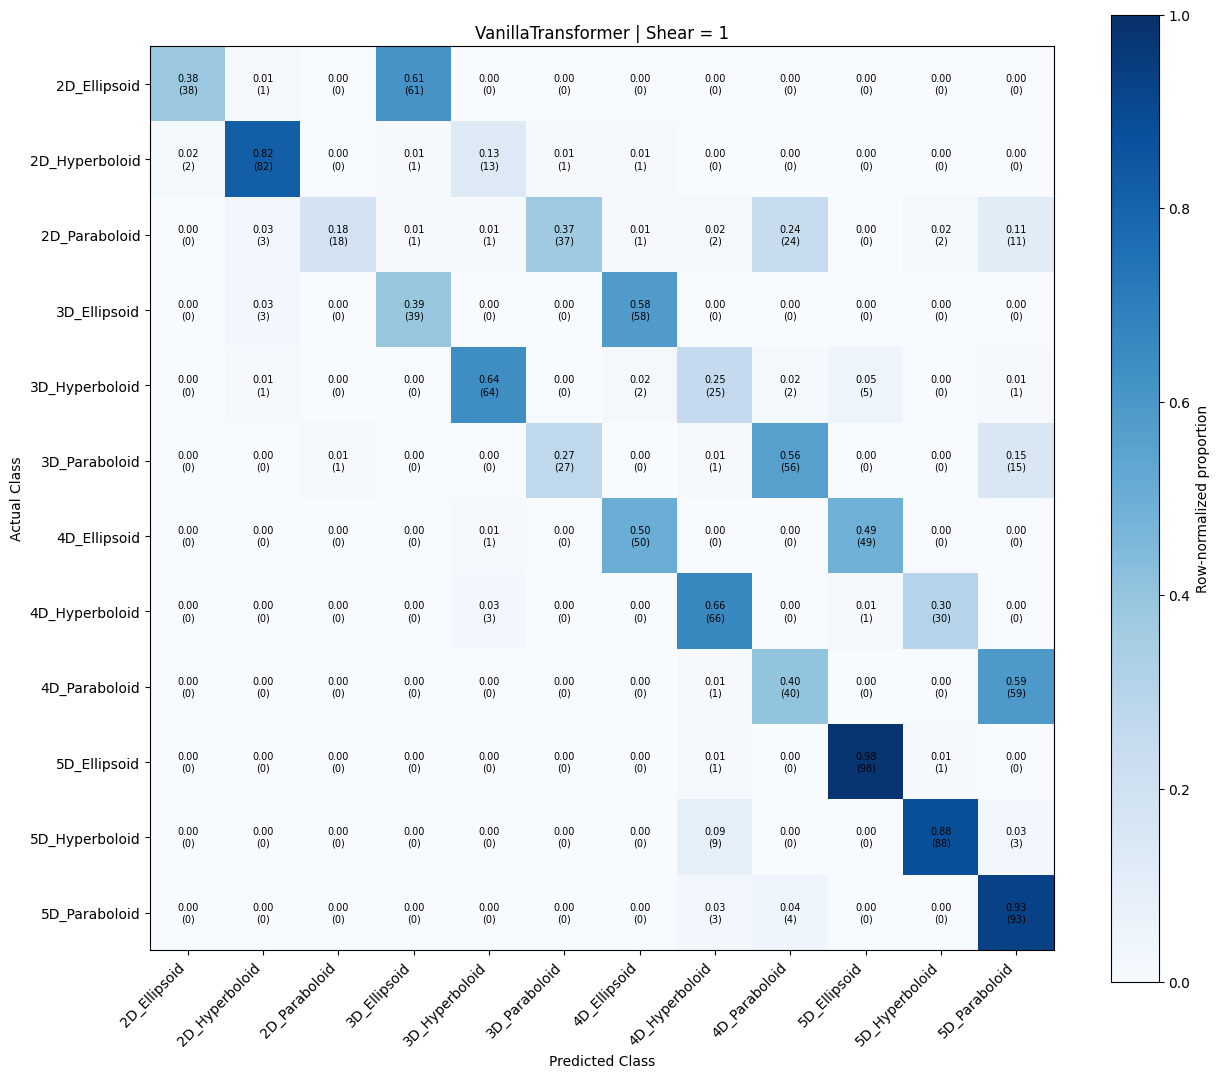

VanillaTransformer | Shear  1 | Accuracy: 0.5858


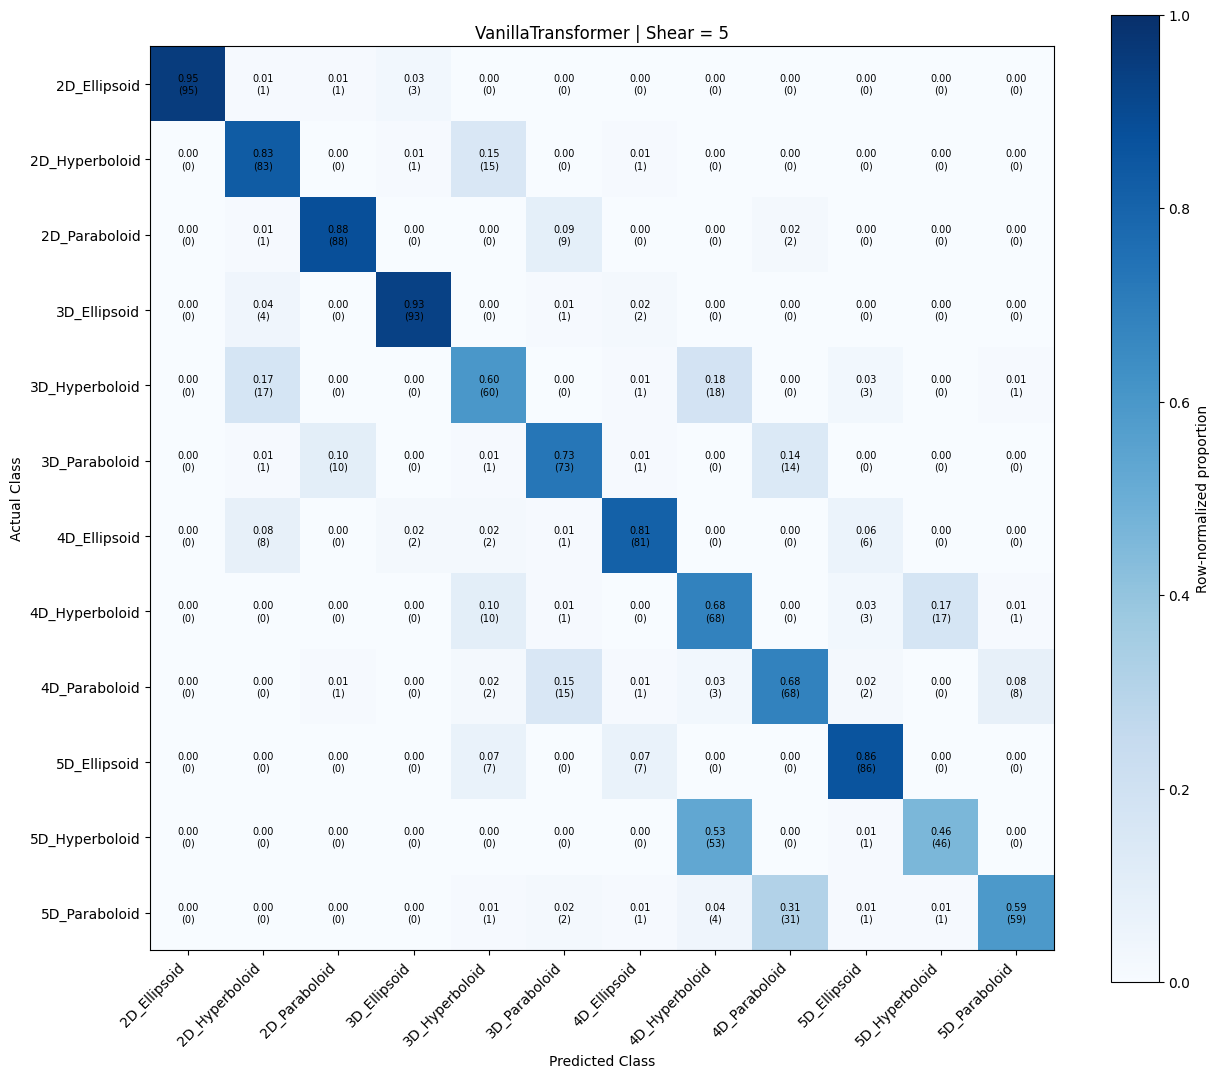

VanillaTransformer | Shear  5 | Accuracy: 0.7500


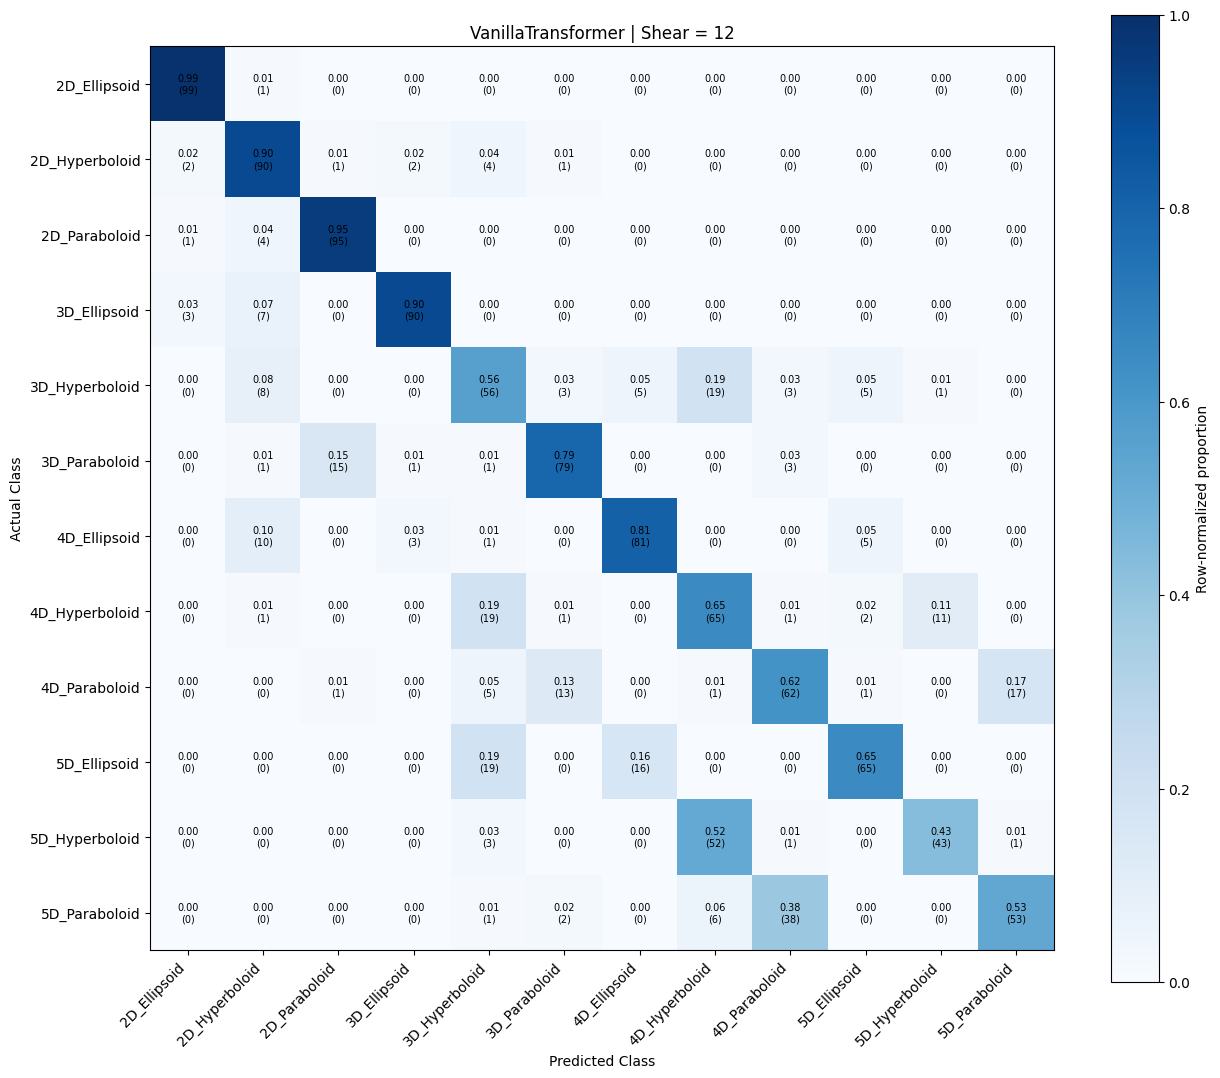

VanillaTransformer | Shear 12 | Accuracy: 0.7317


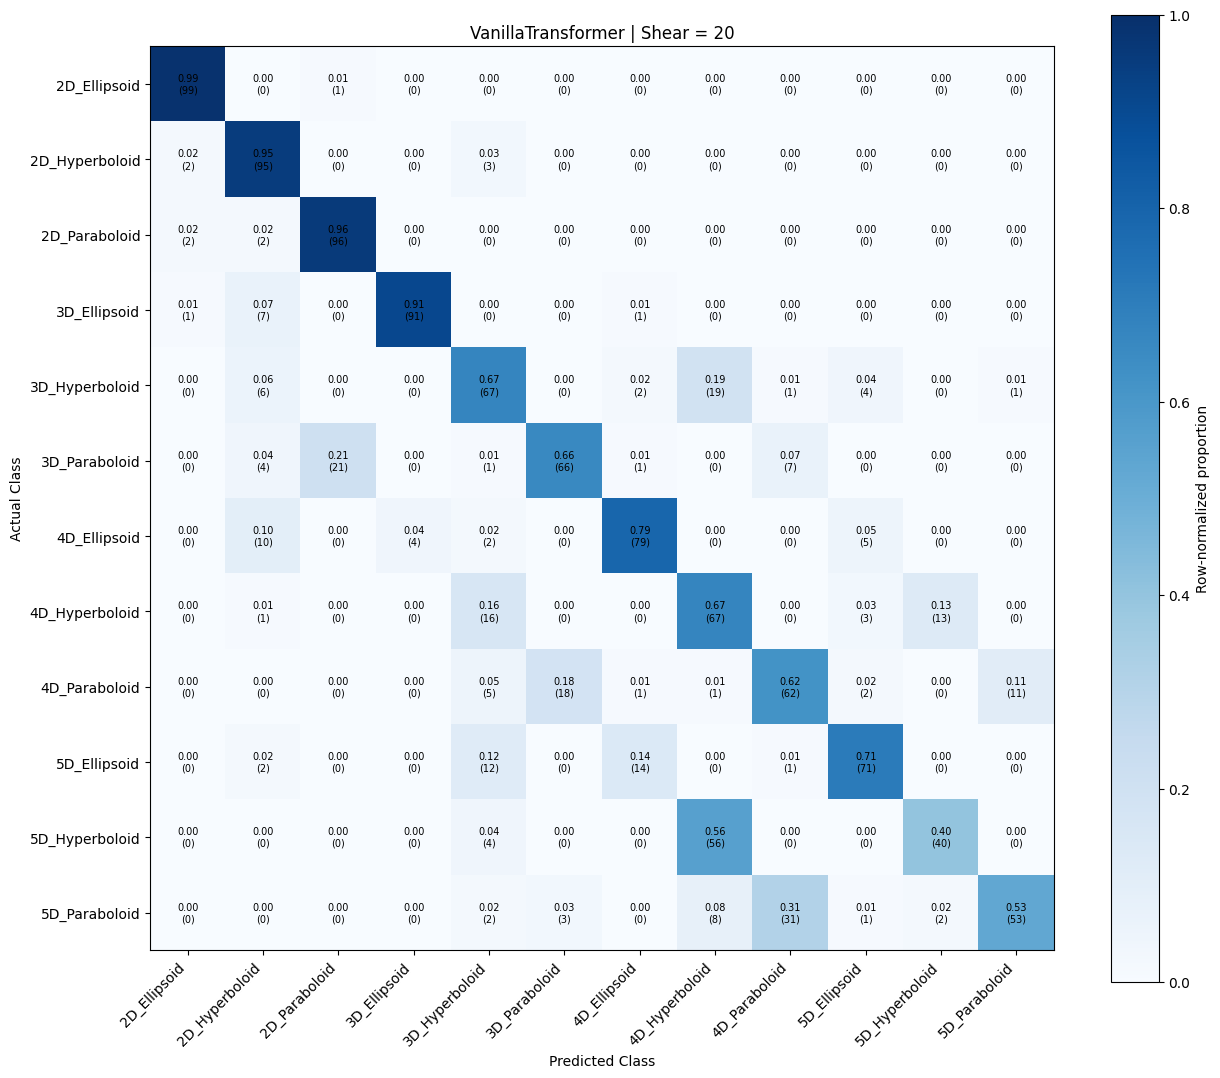

VanillaTransformer | Shear 20 | Accuracy: 0.7383


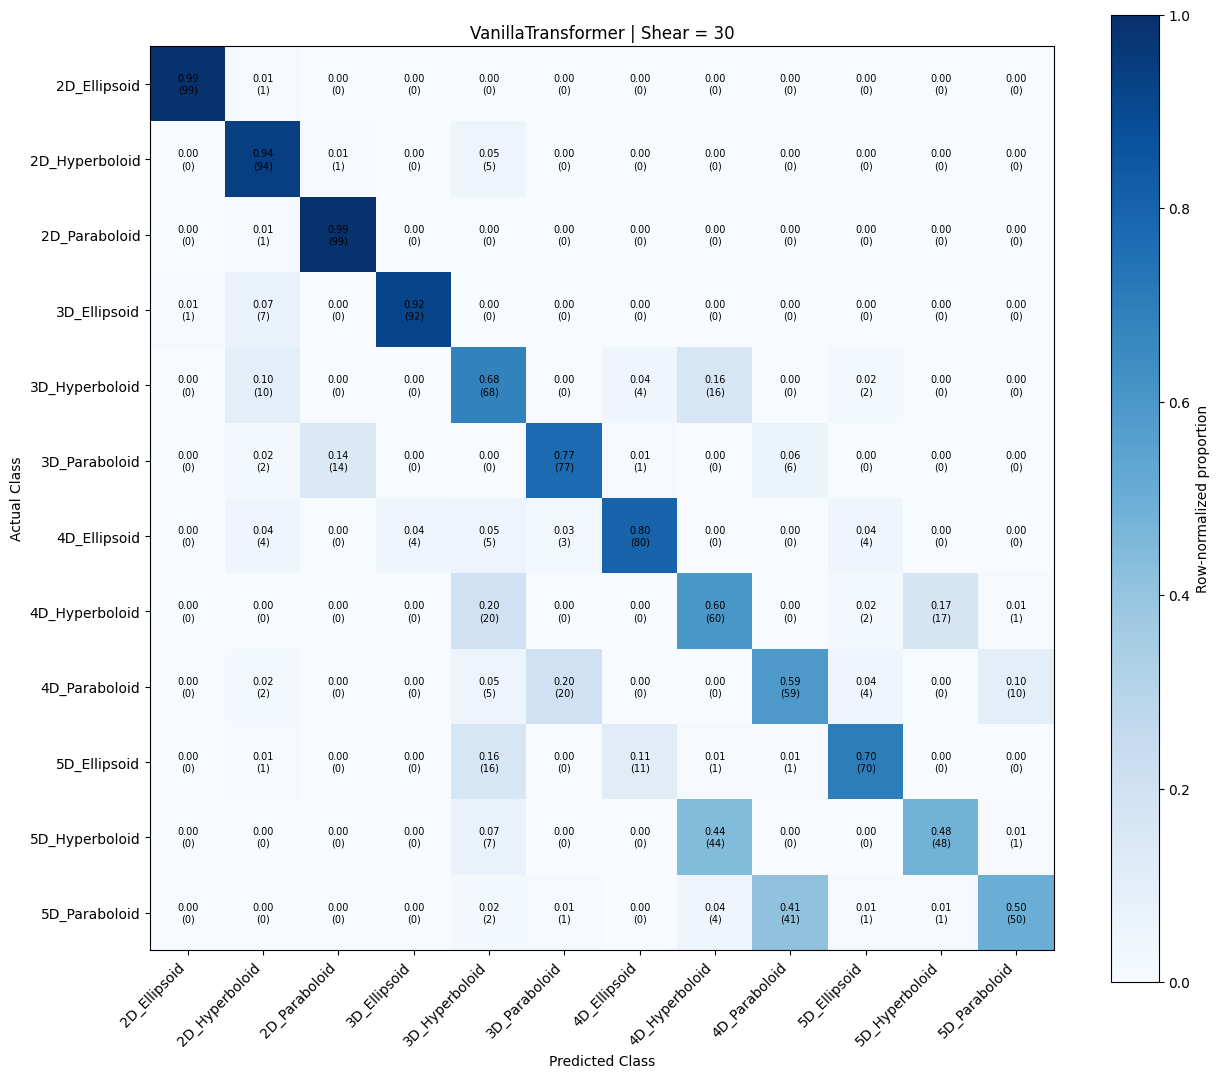

VanillaTransformer | Shear 30 | Accuracy: 0.7467

EVALUATING: CPGMM


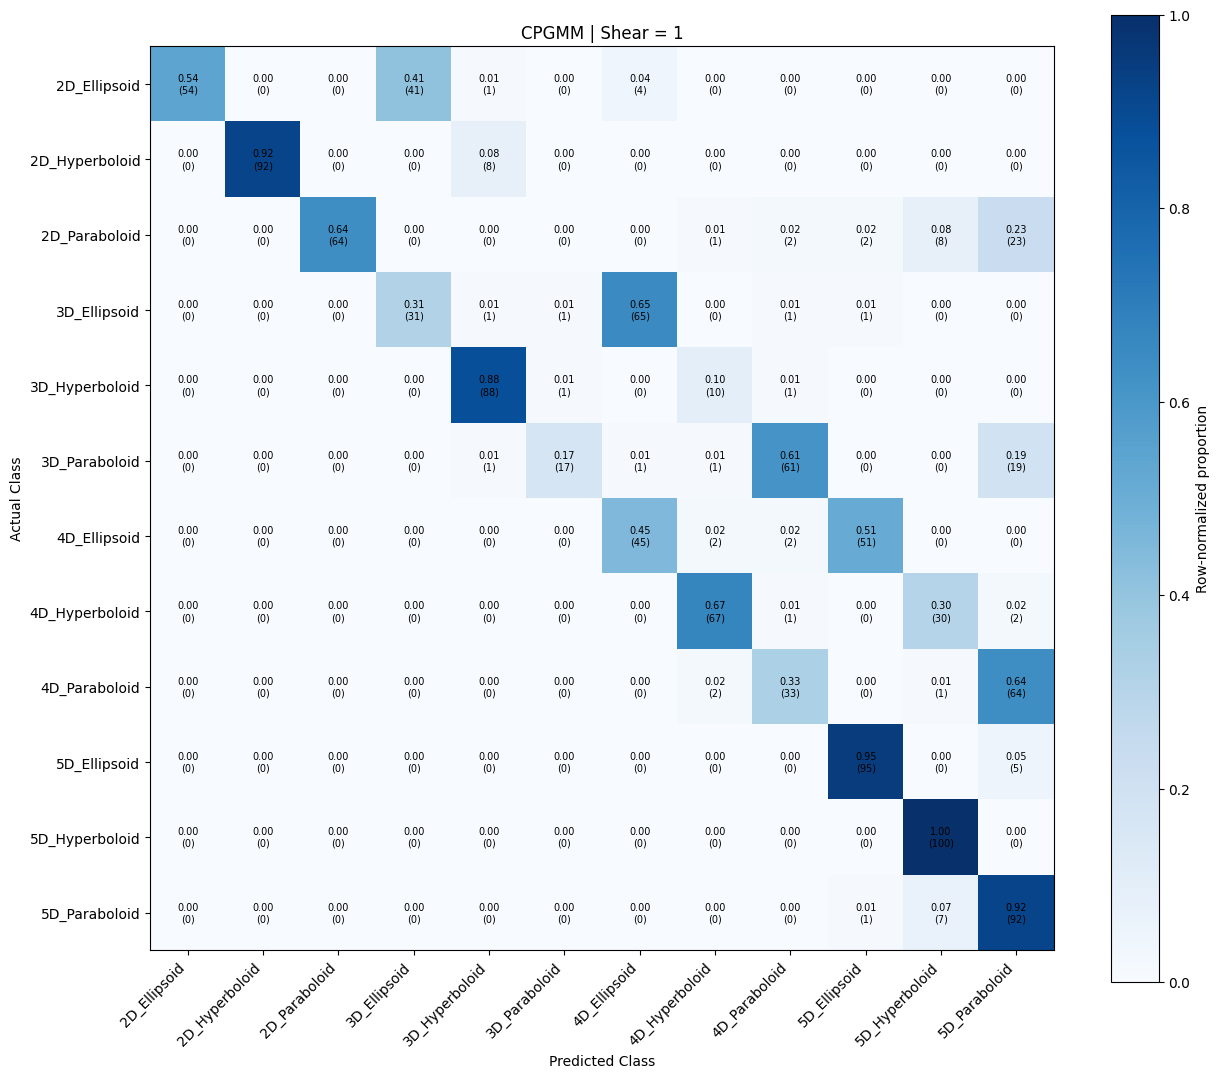

CPGMM | Shear  1 | Accuracy: 0.6483


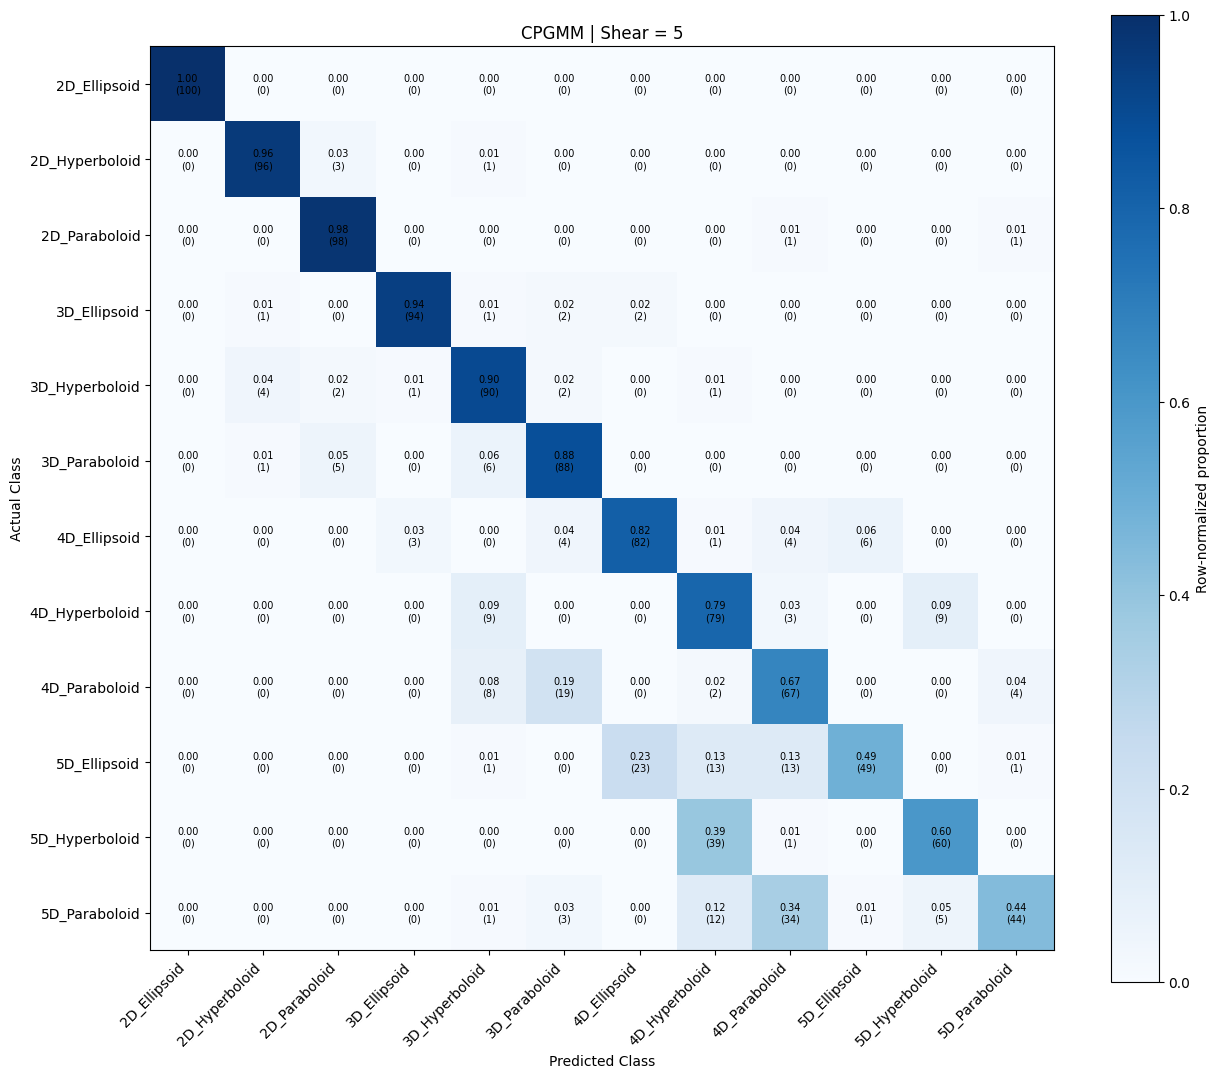

CPGMM | Shear  5 | Accuracy: 0.7892


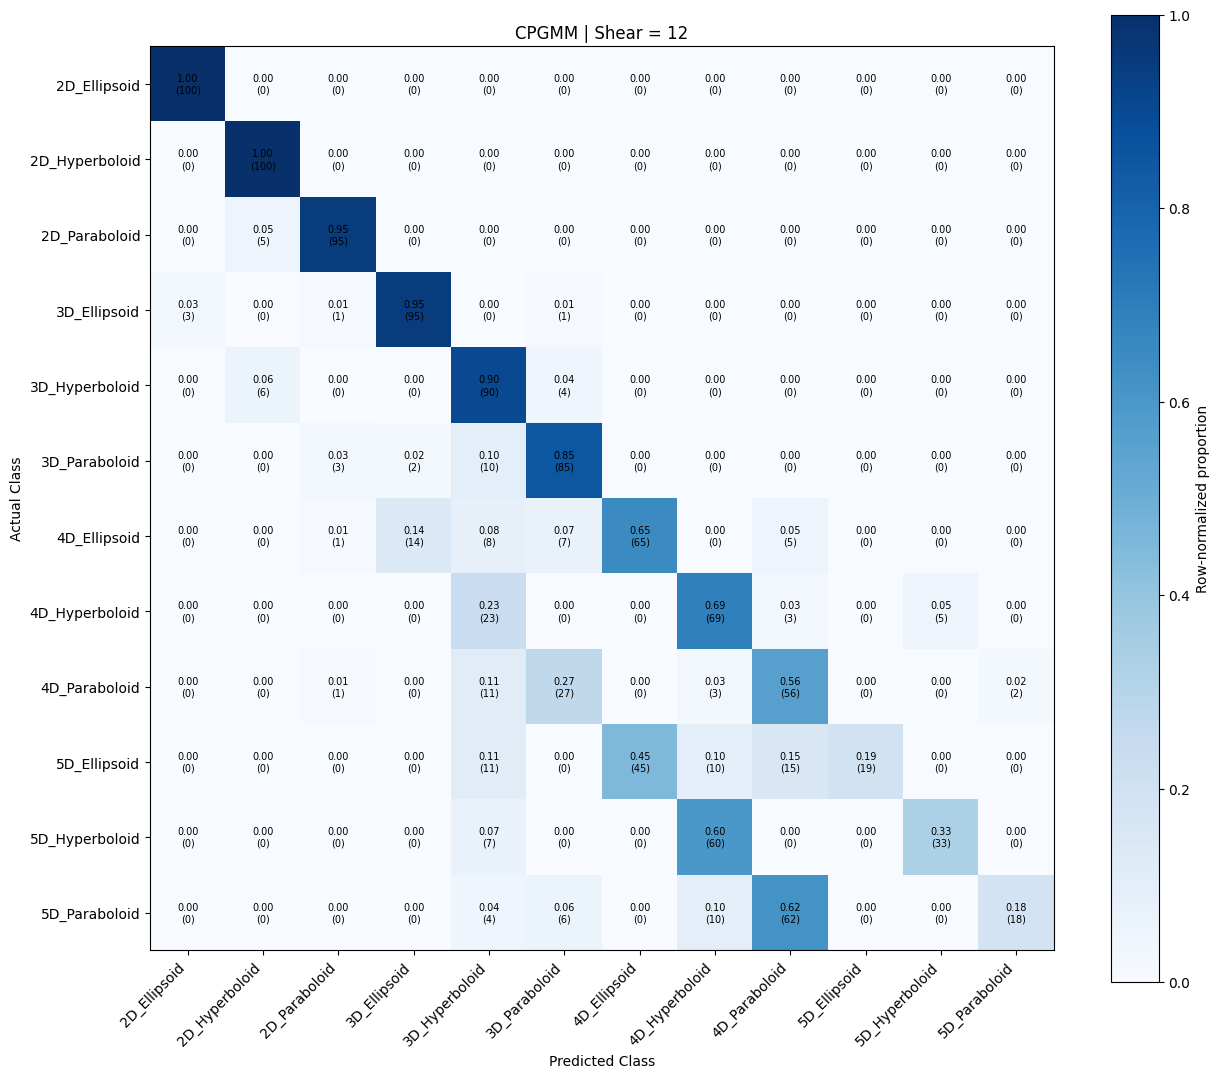

CPGMM | Shear 12 | Accuracy: 0.6875


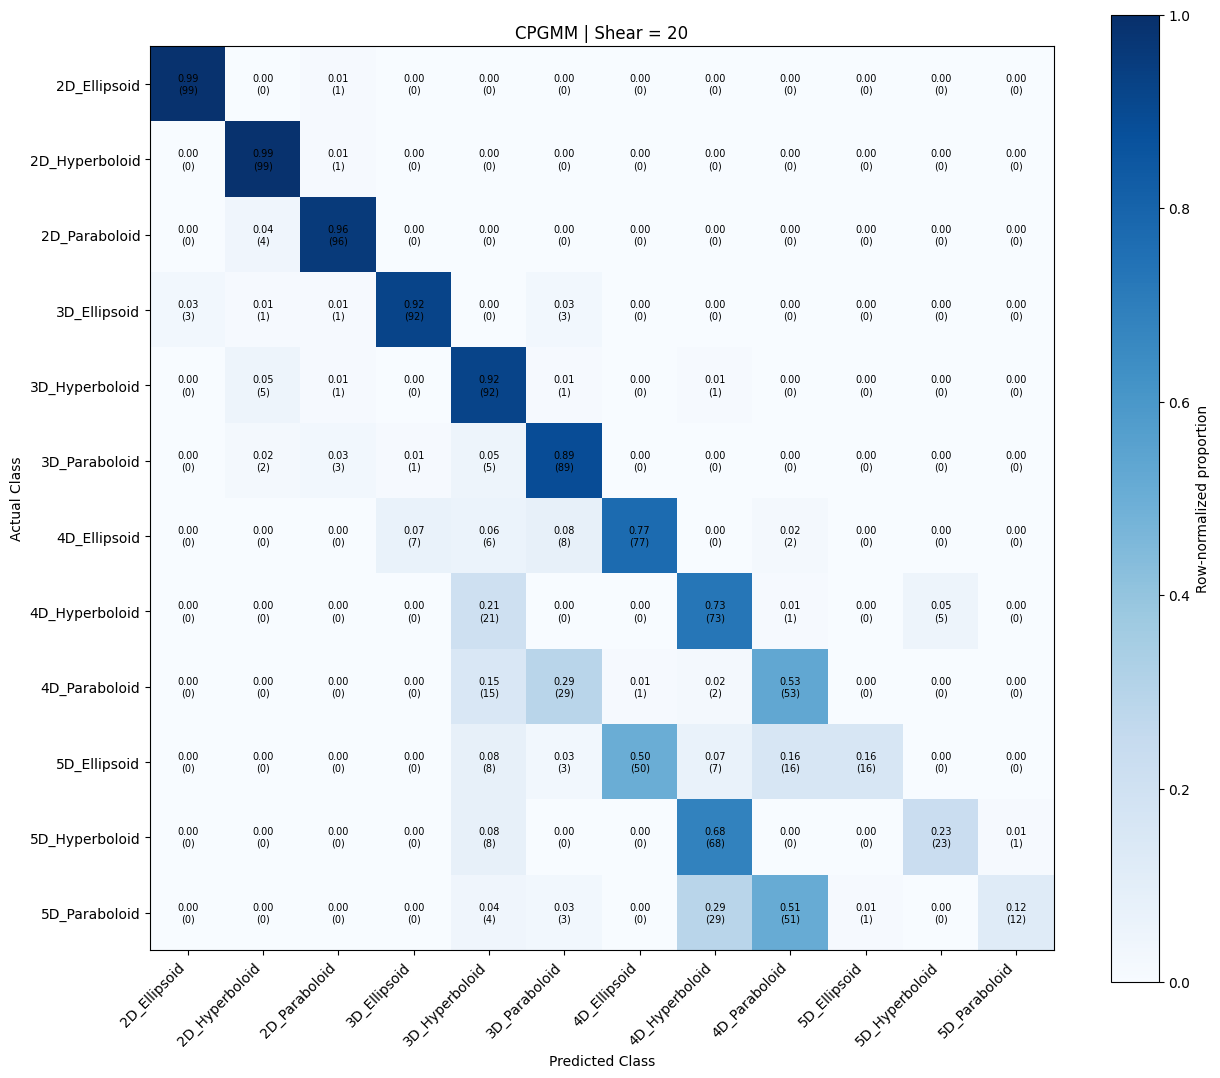

CPGMM | Shear 20 | Accuracy: 0.6842


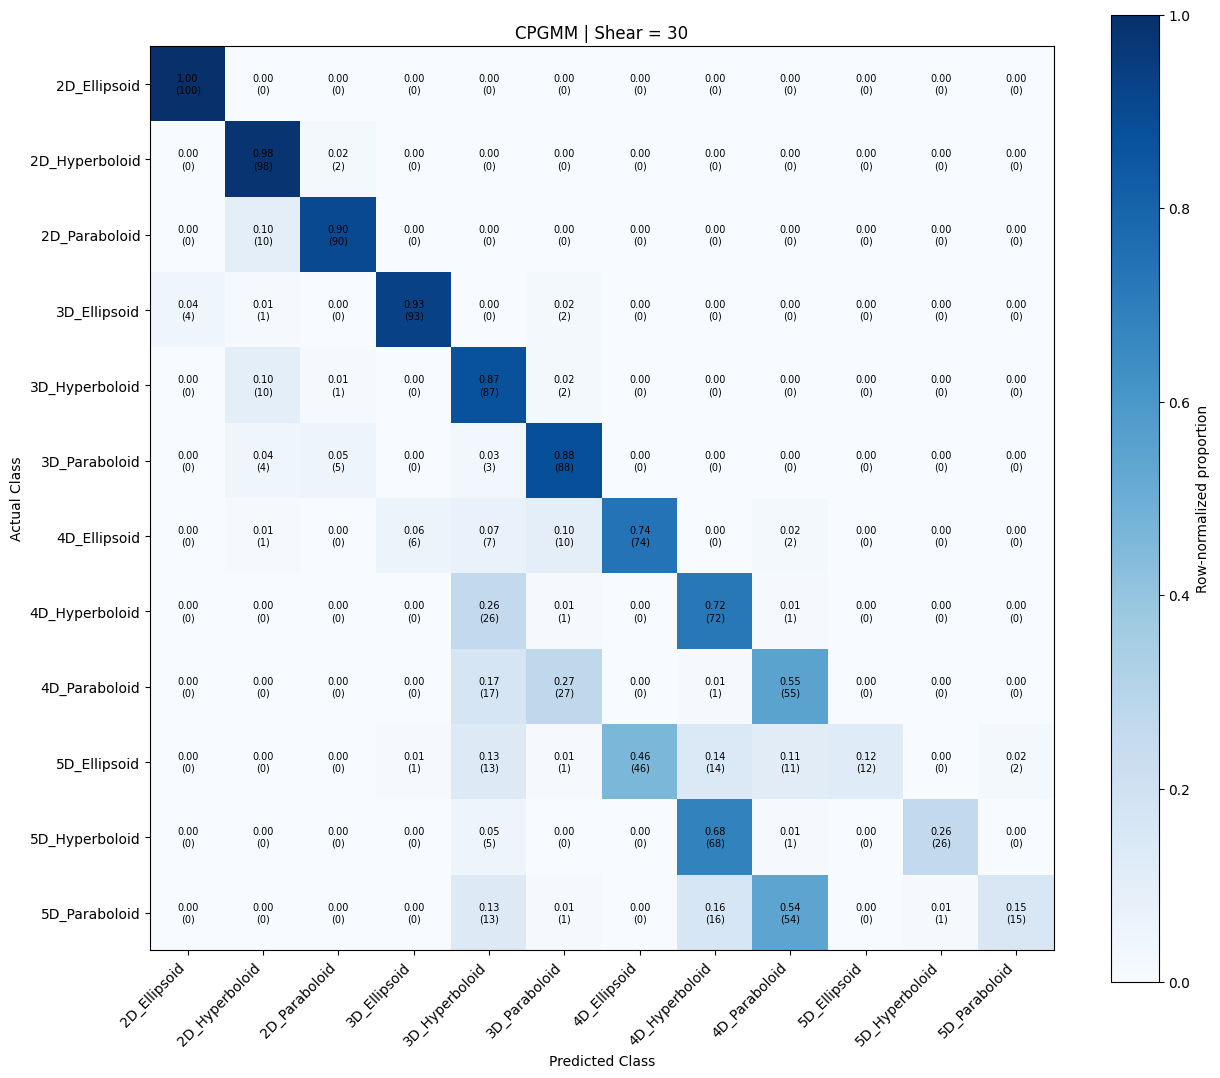

CPGMM | Shear 30 | Accuracy: 0.6750

FINAL ACCURACY COMPARISON


Model,CPGMM,PointNet,VanillaTransformer
Shear,,,
1,0.648333,0.706667,0.585833
5,0.789167,0.805000,0.750000
12,0.687500,0.758333,0.731667
20,0.684167,0.738333,0.738333
30,0.675000,0.732500,0.746667



Results saved to: /kaggle/working/quadratic_5D_experiment/confusion_matrix_evaluation


In [11]:

# ============================================================
# OOD CONFUSION MATRIX EVALUATION
# Current TRAIN-ONLY 5D experiment
# ============================================================

import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

MODEL_NAMES = [
    "PointNet",
    "VanillaTransformer",
    "CPGMM"
]

SHEAR_LEVELS = [1, 5, 12, 20, 30]

TEST_CLOUDS_PER_CLASS = 100
TEST_NOISE = 0.10

OUTPUT_DIR = Path(OUT_DIR) / "confusion_matrix_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. CHECK REQUIRED DEFINITIONS
# ------------------------------------------------------------

required = [
    "sample_intrinsic_geometry",
    "embed_in_5d",
    "transform_cloud",
    "build_model",
    "evaluate_model",
    "iterate_batches",
    "CLASS_NAMES",
    "CFG",
    "DEVICE"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(f"Missing definitions: {missing}")

if len(CLASS_NAMES) != 12:
    raise ValueError("Expected 12 classification classes.")

# ------------------------------------------------------------
# 3. VERIFY CHECKPOINTS
# ------------------------------------------------------------

CHECKPOINTS = {
    name: (
        Path(OUT_DIR) / name /
        "checkpoints" / "best_validation.pt"
    )
    for name in MODEL_NAMES
}

for name, path in CHECKPOINTS.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {name} checkpoint: {path.resolve()}"
        )

print("All three best-validation checkpoints verified.")

# ------------------------------------------------------------
# 4. EXPLICIT OOD DATASET GENERATOR
# ------------------------------------------------------------

def generate_ood_dataset(
    clouds_per_class,
    shear_magnitude,
    noise_level,
    seed
):

    random.seed(seed)
    np.random.seed(seed)

    all_clouds = []
    all_labels = []

    for dim_idx, intrinsic_dim in enumerate(CFG.intrinsic_dims):

        for family_idx, family in enumerate(CFG.families):

            class_id = (
                dim_idx * len(CFG.families) + family_idx
            )

            for _ in range(clouds_per_class):

                X_intrinsic = sample_intrinsic_geometry(
                    intrinsic_dim,
                    family,
                    CFG.num_points
                )

                X_5d = embed_in_5d(
                    X_intrinsic,
                    intrinsic_dim
                )

                X_final = transform_cloud(
                    X_5d,
                    shear_magnitude,
                    noise_level
                )

                all_clouds.append(X_final)
                all_labels.append(class_id)

    X = np.asarray(all_clouds, dtype=np.float32)
    y = np.asarray(all_labels, dtype=np.int64)

    # Shuffle deterministically.
    indices = np.random.permutation(len(y))

    X = X[indices]
    y = y[indices]

    return X, y


# ------------------------------------------------------------
# 5. GENERATE FIXED OOD TEST DATASETS
# ------------------------------------------------------------

TEST_DATASETS = {}

for shear in SHEAR_LEVELS:

    X_test, y_test = generate_ood_dataset(
        clouds_per_class=TEST_CLOUDS_PER_CLASS,
        shear_magnitude=shear,
        noise_level=TEST_NOISE,
        seed=42 + shear
    )

    # Keep tensors on the same device as the trained models.
    X_test = torch.from_numpy(X_test).to(DEVICE)
    y_test = torch.from_numpy(y_test).to(DEVICE)

    TEST_DATASETS[shear] = (X_test, y_test)

    print(
        f"Shear {shear}: "
        f"X={tuple(X_test.shape)}, "
        f"y={tuple(y_test.shape)}"
    )

# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

def compute_confusion_matrix(y_true, y_pred):

    cm = np.zeros((12, 12), dtype=np.int64)

    np.add.at(
        cm,
        (y_true.astype(int), y_pred.astype(int)),
        1
    )

    return cm


# ------------------------------------------------------------
# 7. BATCHED PREDICTION
# evaluate_model in your current script returns only
# loss and accuracy, so collect predictions separately.
# ------------------------------------------------------------

@torch.no_grad()
def get_predictions(model, X, y):

    model.eval()

    all_true = []
    all_pred = []

    for xb, yb in iterate_batches(
        X,
        y,
        CFG.batch_size,
        shuffle=False
    ):

        logits = get_logits(model(xb))
        predictions = logits.argmax(dim=1)

        all_true.extend(yb.detach().cpu().numpy())
        all_pred.extend(predictions.detach().cpu().numpy())

    return (
        np.asarray(all_true),
        np.asarray(all_pred)
    )


# ------------------------------------------------------------
# 8. CONFUSION MATRIX PLOT
# ------------------------------------------------------------

def plot_confusion_matrix(cm, title, save_path):

    row_totals = cm.sum(axis=1, keepdims=True)

    normalized = cm / np.maximum(row_totals, 1)

    fig, ax = plt.subplots(figsize=(13, 11))

    im = ax.imshow(
        normalized,
        cmap="Blues",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    positions = np.arange(12)

    ax.set_xticks(positions)
    ax.set_yticks(positions)

    ax.set_xticklabels(
        CLASS_NAMES,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(CLASS_NAMES)

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.set_title(title)

    for i in range(12):
        for j in range(12):

            ax.text(
                j,
                i,
                f"{normalized[i, j]:.2f}\n({cm[i, j]})",
                ha="center",
                va="center",
                fontsize=7
            )

    fig.colorbar(
        im,
        ax=ax,
        label="Row-normalized proportion"
    )

    fig.tight_layout()
    fig.savefig(save_path, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 9. EVALUATE ALL THREE MODELS
# ------------------------------------------------------------

ALL_MATRICES = {}
ALL_METRICS = []

for model_name in MODEL_NAMES:

    print("\n" + "=" * 70)
    print("EVALUATING:", model_name)
    print("=" * 70)

    checkpoint = torch.load(
        CHECKPOINTS[model_name],
        map_location=DEVICE,
        weights_only=False
    )

    model = build_model(model_name).to(DEVICE)

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    model_dir = OUTPUT_DIR / model_name
    model_dir.mkdir(parents=True, exist_ok=True)

    ALL_MATRICES[model_name] = {}

    for shear in SHEAR_LEVELS:

        X_test, y_test = TEST_DATASETS[shear]

        y_true, y_pred = get_predictions(
            model,
            X_test,
            y_test
        )

        cm = compute_confusion_matrix(
            y_true,
            y_pred
        )

        accuracy = float(np.trace(cm) / cm.sum())

        ALL_MATRICES[model_name][shear] = cm

        # Save raw matrix.
        pd.DataFrame(
            cm,
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        ).to_csv(
            model_dir / f"confusion_shear_{shear}.csv"
        )

        # Save normalized matrix.
        plot_confusion_matrix(
            cm,
            f"{model_name} | Shear = {shear}",
            model_dir / f"confusion_shear_{shear}.png"
        )

        ALL_METRICS.append({
            "Model": model_name,
            "Shear": shear,
            "Accuracy": accuracy,
            "Correct": int(np.trace(cm)),
            "Total": int(cm.sum())
        })

        print(
            f"{model_name} | Shear {shear:2d} | "
            f"Accuracy: {accuracy:.4f}"
        )

    del model
    del checkpoint

    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 10. SAVE FINAL COMPARISON
# ------------------------------------------------------------

METRICS_DF = pd.DataFrame(ALL_METRICS)

METRICS_DF.to_csv(
    OUTPUT_DIR / "accuracy_comparison.csv",
    index=False
)

print("\nFINAL ACCURACY COMPARISON")

display(
    METRICS_DF.pivot(
        index="Shear",
        columns="Model",
        values="Accuracy"
    )
)

print("\nResults saved to:", OUTPUT_DIR.resolve())


In [20]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

CLASS_NAMES = [
    "2D_Ellipsoid", "2D_Hyperboloid", "2D_Paraboloid",
    "3D_Ellipsoid", "3D_Hyperboloid", "3D_Paraboloid",
    "4D_Ellipsoid", "4D_Hyperboloid", "4D_Paraboloid",
    "5D_Ellipsoid", "5D_Hyperboloid", "5D_Paraboloid"
]

DIMENSIONS = ["2D", "3D", "4D", "5D"]

def dimension_analysis(cm):
    cm = np.asarray(cm)

    if cm.shape != (12, 12):
        raise ValueError("Expected a 12x12 confusion matrix.")

    dimension_cm = np.zeros((4, 4), dtype=int)

    class_dimensions = [name.split("_")[0] for name in CLASS_NAMES]

    for i, actual_dim in enumerate(DIMENSIONS):
        for j, predicted_dim in enumerate(DIMENSIONS):

            actual_idx = [
                k for k, d in enumerate(class_dimensions)
                if d == actual_dim
            ]

            predicted_idx = [
                k for k, d in enumerate(class_dimensions)
                if d == predicted_dim
            ]

            dimension_cm[i, j] = cm[np.ix_(
                actual_idx, predicted_idx
            )].sum()

    total = dimension_cm.sum()
    accuracy = np.trace(dimension_cm) / total

    recalls = np.diag(dimension_cm) / dimension_cm.sum(axis=1)

    print(f"\nDimension-only accuracy: {accuracy:.4%}")

    print("\nPer-dimension recall:")
    for dim, recall in zip(DIMENSIONS, recalls):
        print(f"{dim}: {recall:.2%}")

    print("\nDimension confusion matrix:")
    display(pd.DataFrame(
        dimension_cm,
        index=[f"Actual {d}" for d in DIMENSIONS],
        columns=[f"Predicted {d}" for d in DIMENSIONS]
    ))

    return accuracy, recalls, dimension_cm


cm = confusion_matrix(y_true, y_pred, labels=np.arange(12))
# Initialize this once, before the evaluation loops
confusion_matrices = {}

# Inside the model/shear evaluation loop:
confusion_matrices.setdefault(model_name, {})
confusion_matrices[model_name][shear] = cm.copy()

dimension_results = {}

for model_name in confusion_matrices:
    dimension_results[model_name] = {}

    for shear, cm in confusion_matrices[model_name].items():
        print(f"\n{'='*55}")
        print(f"{model_name} | Shear = {shear}")

        accuracy, recalls, dimension_cm = dimension_analysis(cm)

        dimension_results[model_name][shear] = accuracy * 100

summary = pd.DataFrame(dimension_results).T
summary = summary.reindex(columns=[1, 5, 12, 20, 30])

summary.columns = [f"Shear {s}" for s in summary.columns]

print("\nOVERALL DIMENSION-ONLY ACCURACY (%)")
display(summary.round(2))




PointNet | Shear = 1

Dimension-only accuracy: 69.6667%

Per-dimension recall:
2D: 100.00%
3D: 91.67%
4D: 68.33%
5D: 18.67%

Dimension confusion matrix:


,Predicted 2D,Predicted 3D,Predicted 4D,Predicted 5D
Actual 2D,300,0,0,0
Actual 3D,25,275,0,0
Actual 4D,1,94,205,0
Actual 5D,0,34,210,56



OVERALL DIMENSION-ONLY ACCURACY (%)


,Shear 1,Shear 5,Shear 12,Shear 20,Shear 30
PointNet,69.67,NaN,NaN,NaN,NaN


In [25]:

# ================================================================
# CPGMM HIGH-SHEAR ABLATION STUDY
# Inference-time component ablations | No retraining
#
# Shear: 5, 12, 20, 30
# Checkpoint: best_validation.pt
#
# Ablations:
# 1. Full CPGMM
# 2. No quadratic Veronese token features
# 3. No template-routing contribution
# 4. No geometric attention bias
# ================================================================

import numpy as np
import pandas as pd
import torch
import json
import gc

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    f1_score
)

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

MODEL_NAME = "CPGMM"

SHEAR_LEVELS = [5, 12, 20, 30]

TEST_NOISE = 0.10
TEST_CLOUDS_PER_CLASS = 100

BASE_SEED = 42

CHECKPOINT_PATH = (
    OUT_DIR / MODEL_NAME / "checkpoints" / "best_validation.pt"
)

RESULTS_DIR = OUT_DIR / "CPGMM_high_shear_ablation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

ABLATIONS = [
    "Full CPGMM",
    "No Quadratic Token Features",
    "No Template Routing",
    "No Geometric Attention Bias"
]

print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint exists:", CHECKPOINT_PATH.exists())

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(CHECKPOINT_PATH)


# ------------------------------------------------
# 2. TEST DATA GENERATOR
# ------------------------------------------------

def generate_ablation_test_data(shear, seed):

    np.random.seed(seed)

    all_clouds = []
    all_labels = []

    for dim_idx, intrinsic_dim in enumerate(CFG.intrinsic_dims):

        for family_idx, family in enumerate(CFG.families):

            class_id = (
                dim_idx * len(CFG.families) + family_idx
            )

            for _ in range(TEST_CLOUDS_PER_CLASS):

                X_int = sample_intrinsic_geometry(
                    intrinsic_dim,
                    family,
                    CFG.num_points
                )

                X_5d = embed_in_5d(
                    X_int,
                    intrinsic_dim
                )

                X_final = transform_cloud(
                    X_5d,
                    shear,
                    TEST_NOISE
                )

                all_clouds.append(X_final)
                all_labels.append(class_id)

    X = np.asarray(all_clouds, dtype=np.float32)
    y = np.asarray(all_labels, dtype=np.int64)

    return (
        torch.from_numpy(X).to(DEVICE),
        torch.from_numpy(y).to(DEVICE)
    )


# ------------------------------------------------
# 3. ABLATION HOOKS
# ------------------------------------------------

def disable_quadratic_token_features(model):
    """
    Zero the 21 Veronese token channels entering the embedding.

    The algebraic coefficient estimator, routing and geometric
    attention pathways remain active.
    """

    def hook(module, inputs):
        x = inputs[0].clone()

        # First 5 channels = original coordinates.
        # Last 21 channels = quadratic Veronese features.
        x[..., 5:] = 0.0

        return (x,)

    return model.embedding.register_forward_pre_hook(hook)


def disable_template_routing(model):
    """
    Zero the routed template embedding before it is added
    to the token representations.
    """

    def hook(module, inputs, output):
        return torch.zeros_like(output)

    return model.template_projection.register_forward_hook(hook)


def disable_geometric_attention_bias(model):
    """
    Set the learned geometric attention coefficient alpha to zero.
    """

    original_alpha = model.alpha.detach().clone()

    with torch.no_grad():
        model.alpha.zero_()

    return original_alpha


# ------------------------------------------------
# 4. PREDICTION COLLECTION
# ------------------------------------------------

@torch.no_grad()
def collect_ablation_predictions(model, X, y):

    model.eval()

    predictions = []
    targets = []

    for xb, yb in iterate_batches(
        X,
        y,
        CFG.batch_size,
        shuffle=False
    ):

        logits = get_logits(model(xb))

        pred = logits.argmax(dim=1)

        predictions.append(pred.cpu().numpy())
        targets.append(yb.cpu().numpy())

    return (
        np.concatenate(targets),
        np.concatenate(predictions)
    )


# ------------------------------------------------
# 5. DIMENSION-ONLY METRICS
# ------------------------------------------------

DIMENSIONS = ["2D", "3D", "4D", "5D"]

CLASS_DIMENSIONS = np.repeat(DIMENSIONS, 3)


def calculate_dimension_metrics(cm):

    dimension_cm = np.zeros((4, 4), dtype=int)

    for i, actual_dim in enumerate(DIMENSIONS):

        for j, predicted_dim in enumerate(DIMENSIONS):

            actual_idx = np.where(
                CLASS_DIMENSIONS == actual_dim
            )[0]

            predicted_idx = np.where(
                CLASS_DIMENSIONS == predicted_dim
            )[0]

            dimension_cm[i, j] = cm[np.ix_(
                actual_idx,
                predicted_idx
            )].sum()

    row_totals = dimension_cm.sum(axis=1)

    recalls = np.divide(
        np.diag(dimension_cm),
        row_totals,
        out=np.zeros(4, dtype=float),
        where=row_totals != 0
    )

    dimension_accuracy = (
        np.trace(dimension_cm) / dimension_cm.sum()
    )

    return dimension_accuracy, recalls, dimension_cm


# ------------------------------------------------
# 6. LOAD TRAINED CHECKPOINT
# ------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("\nLoaded CPGMM checkpoint")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation accuracy:", checkpoint["best_val_accuracy"])

# ------------------------------------------------
# 7. MAIN ABLATION EXPERIMENT
# ------------------------------------------------

all_results = []
all_confusion_matrices = {}

for shear in SHEAR_LEVELS:

    print("\n" + "=" * 75)
    print(f"HIGH-SHEAR EVALUATION | SHEAR = {shear}")
    print("=" * 75)

    # One dataset shared by every ablation at this shear.
    X_TEST, Y_TEST = generate_ablation_test_data(
        shear=shear,
        seed=BASE_SEED + shear
    )

    y_true_reference = Y_TEST.cpu().numpy()

    print("Test samples:", len(y_true_reference))

    for ablation_name in ABLATIONS:

        print(f"\nRunning: {ablation_name}")

        # Build a fresh model for each intervention.
        model = build_model(MODEL_NAME).to(DEVICE)

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        model.eval()

        hook_handle = None
        original_alpha = None

        # Apply exactly one intervention.
        if ablation_name == "No Quadratic Token Features":

            hook_handle = disable_quadratic_token_features(
                model
            )

        elif ablation_name == "No Template Routing":

            hook_handle = disable_template_routing(
                model
            )

        elif ablation_name == "No Geometric Attention Bias":

            original_alpha = disable_geometric_attention_bias(
                model
            )

        # Collect predictions.
        y_true, y_pred = collect_ablation_predictions(
            model,
            X_TEST,
            Y_TEST
        )

        # Ensure identical ground-truth samples.
        assert np.array_equal(
            y_true,
            y_true_reference
        )

        # Remove hooks / restore model parameter.
        if hook_handle is not None:
            hook_handle.remove()

        if original_alpha is not None:
            with torch.no_grad():
                model.alpha.copy_(original_alpha)

        # Original 12-class confusion matrix.
        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=np.arange(CFG.num_classes)
        )

        # Metrics.
        accuracy = accuracy_score(y_true, y_pred) * 100

        macro_f1 = f1_score(
            y_true,
            y_pred,
            labels=np.arange(CFG.num_classes),
            average="macro",
            zero_division=0
        ) * 100

        dim_accuracy, dim_recalls, dim_cm = (
            calculate_dimension_metrics(cm)
        )

        result = {
            "Shear": shear,
            "Configuration": ablation_name,
            "12-Class Accuracy (%)": accuracy,
            "Dimension Accuracy (%)": dim_accuracy * 100,
            "Macro F1 (%)": macro_f1,
            "2D Recall (%)": dim_recalls[0] * 100,
            "3D Recall (%)": dim_recalls[1] * 100,
            "4D Recall (%)": dim_recalls[2] * 100,
            "5D Recall (%)": dim_recalls[3] * 100
        }

        all_results.append(result)

        all_confusion_matrices[
            (shear, ablation_name)
        ] = {
            "12_class": cm,
            "dimension": dim_cm
        }

        print(
            f"12-class accuracy: {accuracy:.2f}% | "
            f"Dimension accuracy: {dim_accuracy * 100:.2f}% | "
            f"Macro F1: {macro_f1:.2f}%"
        )

        del model
        torch.cuda.empty_cache()
        gc.collect()

    del X_TEST, Y_TEST
    torch.cuda.empty_cache()
    gc.collect()


# ------------------------------------------------
# 8. RESULTS TABLE
# ------------------------------------------------

results_df = pd.DataFrame(all_results)

print("\n" + "=" * 90)
print("CPGMM HIGH-SHEAR ABLATION RESULTS")
print("=" * 90)

display(
    results_df.round(2)
)


# ------------------------------------------------
# 9. ACCURACY COMPARISON TABLE
# ------------------------------------------------

accuracy_table = results_df.pivot(
    index="Configuration",
    columns="Shear",
    values="12-Class Accuracy (%)"
)

accuracy_table = accuracy_table.reindex(ABLATIONS)

print("\n12-CLASS ACCURACY (%)")
display(accuracy_table.round(2))


# ------------------------------------------------
# 10. DIMENSION ACCURACY COMPARISON
# ------------------------------------------------

dimension_table = results_df.pivot(
    index="Configuration",
    columns="Shear",
    values="Dimension Accuracy (%)"
)

dimension_table = dimension_table.reindex(ABLATIONS)

print("\nDIMENSION-ONLY ACCURACY (%)")
display(dimension_table.round(2))


# ------------------------------------------------
# 11. COMPONENT CONTRIBUTION ANALYSIS
# ------------------------------------------------

full_accuracy = (
    results_df[
        results_df["Configuration"] == "Full CPGMM"
    ]
    .set_index("Shear")["12-Class Accuracy (%)"]
)

contribution_rows = []

for ablation_name in ABLATIONS[1:]:

    ablated_accuracy = (
        results_df[
            results_df["Configuration"] == ablation_name
        ]
        .set_index("Shear")["12-Class Accuracy (%)"]
    )

    for shear in SHEAR_LEVELS:

        contribution_rows.append({
            "Removed Component": ablation_name,
            "Shear": shear,
            "Full Accuracy (%)": full_accuracy[shear],
            "Ablated Accuracy (%)": ablated_accuracy[shear],
            "Accuracy Difference (pp)": (
                full_accuracy[shear] -
                ablated_accuracy[shear]
            )
        })

contribution_df = pd.DataFrame(contribution_rows)

print("\nCOMPONENT SENSITIVITY: FULL - ABLATED")
display(contribution_df.round(2))


# ------------------------------------------------
# 12. SAVE ALL RESULTS
# ------------------------------------------------

results_df.to_csv(
    RESULTS_DIR / "high_shear_ablation_results.csv",
    index=False
)

accuracy_table.to_csv(
    RESULTS_DIR / "ablation_accuracy_table.csv"
)

dimension_table.to_csv(
    RESULTS_DIR / "ablation_dimension_accuracy.csv"
)

contribution_df.to_csv(
    RESULTS_DIR / "component_sensitivity.csv",
    index=False
)

for (shear, ablation_name), matrices in all_confusion_matrices.items():

    safe_name = ablation_name.lower().replace(" ", "_")

    np.save(
        RESULTS_DIR / f"shear_{shear}_{safe_name}_12class.npy",
        matrices["12_class"]
    )

    np.save(
        RESULTS_DIR / f"shear_{shear}_{safe_name}_dimension.npy",
        matrices["dimension"]
    )

print("\n" + "=" * 75)
print("ABLATION STUDY COMPLETED")
print("Results directory:", RESULTS_DIR)
print("=" * 75)


Checkpoint: /kaggle/working/quadratic_5D_experiment/CPGMM/checkpoints/best_validation.pt
Checkpoint exists: True

Loaded CPGMM checkpoint
Checkpoint epoch: 308
Best validation accuracy: 0.9775

HIGH-SHEAR EVALUATION | SHEAR = 5
Test samples: 1200

Running: Full CPGMM
12-class accuracy: 78.92% | Dimension accuracy: 81.58% | Macro F1: 78.47%

Running: No Quadratic Token Features
12-class accuracy: 8.33% | Dimension accuracy: 25.00% | Macro F1: 1.28%

Running: No Template Routing
12-class accuracy: 38.67% | Dimension accuracy: 51.42% | Macro F1: 33.61%

Running: No Geometric Attention Bias
12-class accuracy: 78.92% | Dimension accuracy: 81.58% | Macro F1: 78.47%

HIGH-SHEAR EVALUATION | SHEAR = 12
Test samples: 1200

Running: Full CPGMM
12-class accuracy: 68.75% | Dimension accuracy: 71.50% | Macro F1: 66.07%

Running: No Quadratic Token Features
12-class accuracy: 8.33% | Dimension accuracy: 25.00% | Macro F1: 1.28%

Running: No Template Routing
12-class accuracy: 39.25% | Dimension accu

,Shear,Configuration,12-Class Accuracy (%),Dimension Accuracy (%),Macro F1 (%),2D Recall (%),3D Recall (%),4D Recall (%),5D Recall (%)
0,5,Full CPGMM,78.92,81.58,78.47,99.00,94.67,79.33,53.33
1,5,No Quadratic Token Features,8.33,25.00,1.28,100.00,0.00,0.00,0.00
2,5,No Template Routing,38.67,51.42,33.61,66.33,51.00,87.33,1.00
3,5,No Geometric Attention Bias,78.92,81.58,78.47,99.00,94.67,79.33,53.33
4,12,Full CPGMM,68.75,71.50,66.07,100.00,95.67,67.00,23.33
5,12,No Quadratic Token Features,8.33,25.00,1.28,100.00,0.00,0.00,0.00
6,12,No Template Routing,39.25,53.00,34.66,76.00,47.33,85.00,3.67
7,12,No Geometric Attention Bias,68.75,71.50,66.07,100.00,95.67,67.00,23.33
8,20,Full CPGMM,68.42,70.42,64.72,100.00,94.33,69.67,17.67
9,20,No Quadratic Token Features,8.33,25.00,1.28,100.00,0.00,0.00,0.00



12-CLASS ACCURACY (%)


Shear,5,12,20,30
Configuration,,,,
Full CPGMM,78.92,68.75,68.42,67.50
No Quadratic Token Features,8.33,8.33,8.33,8.33
No Template Routing,38.67,39.25,41.83,41.00
No Geometric Attention Bias,78.92,68.75,68.42,67.50



DIMENSION-ONLY ACCURACY (%)


Shear,5,12,20,30
Configuration,,,,
Full CPGMM,81.58,71.5,70.42,69.67
No Quadratic Token Features,25.00,25.0,25.00,25.00
No Template Routing,51.42,53.0,56.00,55.50
No Geometric Attention Bias,81.58,71.5,70.42,69.67



COMPONENT SENSITIVITY: FULL - ABLATED


,Removed Component,Shear,Full Accuracy (%),Ablated Accuracy (%),Accuracy Difference (pp)
0,No Quadratic Token Features,5,78.92,8.33,70.58
1,No Quadratic Token Features,12,68.75,8.33,60.42
2,No Quadratic Token Features,20,68.42,8.33,60.08
3,No Quadratic Token Features,30,67.50,8.33,59.17
4,No Template Routing,5,78.92,38.67,40.25
5,No Template Routing,12,68.75,39.25,29.50
6,No Template Routing,20,68.42,41.83,26.58
7,No Template Routing,30,67.50,41.00,26.50
8,No Geometric Attention Bias,5,78.92,78.92,0.00
9,No Geometric Attention Bias,12,68.75,68.75,0.00



ABLATION STUDY COMPLETED
Results directory: /kaggle/working/quadratic_5D_experiment/CPGMM_high_shear_ablation


In [31]:

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import f1_score, confusion_matrix

# ============================================================
# SELF-CONTAINED 2D + 5D RESTRICTED EVALUATION
# Same evaluation setup: shear=1, noise=0.10, seed=43
# ============================================================

SHEAR = 1
NOISE = 0.10
SEED = 43
CLOUDS_PER_CLASS = 100
NUM_POINTS = 256

CLASS_NAMES = [
    "2D_Ellipsoid", "2D_Hyperboloid", "2D_Paraboloid",
    "3D_Ellipsoid", "3D_Hyperboloid", "3D_Paraboloid",
    "4D_Ellipsoid", "4D_Hyperboloid", "4D_Paraboloid",
    "5D_Ellipsoid", "5D_Hyperboloid", "5D_Paraboloid"
]

FAMILIES = ["Ellipsoid", "Hyperboloid", "Paraboloid"]
DIMS = [2, 3, 4, 5]

RETAINED_CLASSES = [0, 1, 2, 9, 10, 11]
MODEL_NAMES = ["PointNet", "VanillaTransformer", "CPGMM"]

# ------------------------------------------------------------
# 1. Generate the shared test dataset
# ------------------------------------------------------------

np.random.seed(SEED)

X_data = []
y_true = []

for dim in DIMS:
    for family_idx, family in enumerate(FAMILIES):

        class_idx = (dim - 2) * 3 + family_idx

        for _ in range(CLOUDS_PER_CLASS):

            X_intrinsic = sample_intrinsic_geometry(
                dim,
                family,
                NUM_POINTS
            )

            X_5d = embed_in_5d(X_intrinsic, dim)

            X_transformed = transform_cloud(
                X_5d,
                SHEAR,
                NOISE
            )

            X_data.append(X_transformed)
            y_true.append(class_idx)

X_data = np.asarray(X_data, dtype=np.float32)
y_true = np.asarray(y_true, dtype=np.int64)

print("Test dataset:", X_data.shape)
print("Labels:", y_true.shape)

# ------------------------------------------------------------
# 2. Load checkpoints and run inference
# ------------------------------------------------------------

predictions = {}

for model_name in MODEL_NAMES:

    checkpoint_path = (
        OUT_DIR / model_name / "checkpoints" / "best_validation.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model = build_model(model_name).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    model_predictions = []

    with torch.no_grad():

        for start in range(0, len(X_data), CFG.batch_size):

            xb = torch.from_numpy(
                X_data[start:start + CFG.batch_size]
            ).to(DEVICE)

            logits = get_logits(model(xb))
            batch_predictions = logits.argmax(dim=1)

            model_predictions.extend(
                batch_predictions.cpu().numpy().tolist()
            )

    predictions[model_name] = np.asarray(
        model_predictions,
        dtype=np.int64
    )

    print(
        f"{model_name}: "
        f"{100 * np.mean(predictions[model_name] == y_true):.2f}% "
        f"full accuracy"
    )

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. Calculate full and restricted metrics
# ------------------------------------------------------------

results = []

mask_2d = np.isin(y_true, [0, 1, 2])
mask_5d = np.isin(y_true, [9, 10, 11])
mask_subset = np.isin(y_true, RETAINED_CLASSES)

for model_name, y_pred in predictions.items():

    full_accuracy = np.mean(y_pred == y_true)

    # Exact accuracy on true 2D and 5D samples.
    # Predictions into 3D/4D remain errors.
    restricted_accuracy = np.mean(
        y_pred[mask_subset] == y_true[mask_subset]
    )

    accuracy_2d = np.mean(
        y_pred[mask_2d] == y_true[mask_2d]
    )

    accuracy_5d = np.mean(
        y_pred[mask_5d] == y_true[mask_5d]
    )

    restricted_macro_f1 = f1_score(
        y_true[mask_subset],
        y_pred[mask_subset],
        labels=RETAINED_CLASSES,
        average="macro",
        zero_division=0
    )

    outside_subset = np.mean(
        ~np.isin(y_pred[mask_subset], RETAINED_CLASSES)
    )

    results.append({
        "Model": model_name,
        "Full 12-Class Accuracy (%)": 100 * full_accuracy,
        "Restricted 2D+5D Accuracy (%)": 100 * restricted_accuracy,
        "2D Exact Accuracy (%)": 100 * accuracy_2d,
        "5D Exact Accuracy (%)": 100 * accuracy_5d,
        "Restricted Macro-F1 (%)": 100 * restricted_macro_f1,
        "Predicted Outside Subset (%)": 100 * outside_subset
    })

results_df = pd.DataFrame(results)

print("\n========== RESTRICTED EVALUATION ==========")
display(results_df.round(2))

# ------------------------------------------------------------
# 4. Per-class recall for the six retained classes
# ------------------------------------------------------------

print("\n========== PER-CLASS RECALL ==========")

for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(12))
    )

    print(f"\n{model_name}")

    for class_idx in RETAINED_CLASSES:

        total = cm[class_idx].sum()
        recall = (
            cm[class_idx, class_idx] / total
            if total else 0
        )

        print(
            f"{CLASS_NAMES[class_idx]:20s}: "
            f"{recall * 100:.2f}%"
        )

# Keep these available for later analysis:
# y_true, predictions, results_df


Test dataset: (1200, 256, 5)
Labels: (1200,)
PointNet: 70.67% full accuracy
VanillaTransformer: 58.58% full accuracy
CPGMM: 64.83% full accuracy

========== RESTRICTED EVALUATION ==========


,Model,Full 12-Class Accuracy (%),Restricted 2D+5D Accuracy (%),2D Exact Accuracy (%),5D Exact Accuracy (%),Restricted Macro-F1 (%),Predicted Outside Subset (%)
0,PointNet,70.67,75.83,55.0,96.67,79.22,20.17
1,VanillaTransformer,58.58,69.50,46.0,93.00,75.66,26.67
2,CPGMM,64.83,82.83,70.0,95.67,86.11,9.50



========== PER-CLASS RECALL ==========

PointNet
2D_Ellipsoid        : 71.00%
2D_Hyperboloid      : 85.00%
2D_Paraboloid       : 9.00%
5D_Ellipsoid        : 99.00%
5D_Hyperboloid      : 96.00%
5D_Paraboloid       : 95.00%

VanillaTransformer
2D_Ellipsoid        : 38.00%
2D_Hyperboloid      : 82.00%
2D_Paraboloid       : 18.00%
5D_Ellipsoid        : 98.00%
5D_Hyperboloid      : 88.00%
5D_Paraboloid       : 93.00%

CPGMM
2D_Ellipsoid        : 54.00%
2D_Hyperboloid      : 92.00%
2D_Paraboloid       : 64.00%
5D_Ellipsoid        : 95.00%
5D_Hyperboloid      : 100.00%
5D_Paraboloid       : 92.00%


In [ ]:
print(5)